# Acondicionamiento de datos – OT Consulting (OTC)
**Etapa 3 del reto · Soporte Analítico para la Toma de Decisiones**

Este cuaderno continúa el análisis exploratorio (`OTC_EDA.ipynb`). Hace cuatro cosas:

1. Recuerda las inconsistencias detectadas en la exploración.
2. Aplica los métodos de corrección definidos a partir de las reglas de negocio R01–R12.
3. Agrega los atributos (métricas y variables de contexto) que faltan para responder las preguntas P1–P11.
4. Exporta las tablas acondicionadas, su metadata, la bitácora de correcciones y las validaciones.

**Fecha de corte:** 17-nov-2026. **Principio de trabajo:** nunca se inventa un dato; lo que no se puede recuperar
queda en nulo con una bandera que lo explica, y el valor original se conserva cuando sirve para auditar.

## 0. Configuración, funciones auxiliares y carga de datos

In [1]:
import os, re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220, 'display.max_columns', 70, 'display.max_colwidth', 60, 'display.max_rows', 150)
try:
    display
except NameError:                      # al correrlo como script (no como cuaderno)
    display = print

FECHA_CORTE = pd.Timestamp('2026-11-17')
HORAS_MES = 160                        # R10: 40 h/semana x 4 semanas

# Carpeta de datos: en Colab es /content (igual que el EDA); en local se toma de la variable OTC_DATA o "."
EN_COLAB = os.path.exists('/content') and 'COLAB_RELEASE_TAG' in os.environ or os.path.exists('/content/Catalogo_Colaboradores.xlsx')
DATA_DIR = '/content' if EN_COLAB else os.environ.get('OTC_DATA', '.')
OUT_DIR = os.path.join(DATA_DIR, 'salida')
os.makedirs(OUT_DIR, exist_ok=True)

ARCHIVOS = {
 'colab': 'Catalogo_Colaboradores.xlsx', 'sueldos': 'Sueldos_Salarios_OTC.xlsx',
 'asig': 'Asignaciones_Colaboradores.xlsx', 'clientes': 'Catalogo_Clientes.xlsx',
 'activos': 'Catalogo_Activos.xlsx', 'inversion': 'Inversion_Activos_OTC.xlsx',
 'roles': 'Catalogo_Roles.xlsx', 'deptos': 'Catalogo_Departamentos.xlsx',
 'habs': 'Catalogo_Habilidades.xlsx', 'matriz': 'Matriz_Habilidades.xlsx',
}
faltan = [f for f in ARCHIVOS.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
if faltan and EN_COLAB:
    from google.colab import files
    files.upload()
raw = {k: pd.read_excel(os.path.join(DATA_DIR, v)) for k, v in ARCHIVOS.items()}
print({k: v.shape for k, v in raw.items()})

{'colab': (107, 45), 'sueldos': (75, 8), 'asig': (31, 11), 'clientes': (12, 13), 'activos': (123, 11), 'inversion': (123, 7), 'roles': (55, 6), 'deptos': (6, 7), 'habs': (71, 6), 'matriz': (54, 77)}


In [2]:
# ---------- Funciones auxiliares ----------
def norm(s):
    """R11: quita espacios sobrantes (inicio, fin y dobles) y pasa a MAYÚSCULAS. Respeta los nulos."""
    out = s.astype('string').str.strip().str.replace(r'\s+', ' ', regex=True).str.upper()
    return out.astype(object).where(out.notna(), np.nan)

def sin_acentos(t):
    return unicodedata.normalize('NFKD', str(t)).encode('ascii', 'ignore').decode().upper().strip()

def a_nulo(s, marcadores):
    """R07/R11: convierte marcadores de relleno (ya normalizados) en nulo."""
    return s.where(~s.isin(marcadores), np.nan)

def a_fecha(s):
    return pd.to_datetime(s, errors='coerce')

def n_cambios(antes, despues):
    """Número de celdas con valor que cambiaron de contenido tras el tratamiento."""
    a = antes.astype('string'); d = despues.astype('string')
    return int((a.notna() & (a != d)).sum())

FIX = []   # bitácora de correcciones (evidencia)
def log_fix(metodo, regla, tabla, campo, problema, accion, antes, despues, hallazgo=''):
    FIX.append(dict(metodo=metodo, regla=regla, tabla=tabla, campo=campo, hallazgo_etapa2=hallazgo, problema=problema,
                    accion=accion, afectados_antes=int(antes), pendientes_despues=int(despues)))

VALID = []  # validaciones automáticas
def valida(nombre, condicion, detalle='', critica=True):
    VALID.append(dict(validacion=nombre, resultado='OK' if bool(condicion) else 'FALLA', detalle=detalle, critica=critica))
    if critica and not condicion:
        print('FALLA CRÍTICA ->', nombre, detalle)

## 1. Recordatorio de inconsistencias identificadas en la exploración (paso A.1)
La bitácora de la Etapa 2 registró 60 hallazgos (21 de severidad alta). La tabla resume los que condicionan las
preguntas de negocio y se usa como punto de partida; cada fila se resuelve (o se deja marcada) en las secciones siguientes.

In [3]:
INCONSISTENCIAS = pd.DataFrame([
 # id, tabla, problema, afectados, universo, severidad, pregunta que bloquea, método
 ('E02','Colaboradores','Puesto = PENDIENTE en activos',29,75,'Alta','P4, P5, P8','M04, M02'),
 ('E03','Colaboradores','Departamento vacío',95,107,'Alta','P5','M04'),
 ('E05','Colaboradores','Claves de nómina solapadas (SMR / OTC-SINDICATO (SMR) / MODALIDAD 40-SMR)',49,107,'Media','P4','M03'),
 ('E06','Colaboradores','Baja sin fecha de baja',18,32,'Alta','P9','M02, M11'),
 ('E07','Colaboradores','Activo con fecha de baja futura',1,75,'Media','P1, P9','M06'),
 ('E08','Colaboradores','Activos con sueldo = 0',5,75,'Alta','P4, P5, P6','M02, M06'),
 ('E09','Colaboradores','Bajas que conservan sueldo > 0',12,32,'Media','P6','M06'),
 ('E13','Colaboradores','Ciudad sin estandarizar',25,107,'Baja','—','M03'),
 ('E12','Colaboradores','SGMM con valores mezclados',10,101,'Media','—','M03'),
 ('E22-E31','Colaboradores','Documentos del expediente pendientes',None,75,'Media/Alta','P10','M11'),
 ('E16-E21','Colaboradores','Datos personales enmascarados (un solo valor)',106,107,'Info','—','M10'),
 ('E32','Sueldos','Departamento vacío (duplica a Colaboradores)',64,75,'Alta','P5','M09'),
 ('E34','Asignaciones','Fecha inicio = 1990-01-01 (relleno)',21,31,'Alta','P2, P5','M02, M05'),
 ('E35','Asignaciones','Fecha fin = texto "Indefinido"',24,31,'Media','P2','M02'),
 ('E36','Asignaciones','Rol asignado = PENDIENTE',29,31,'Alta','P5, P8','M04'),
 ('E37','Asignaciones','Rol interno = PENDIENTE',14,31,'Media','P5','M04'),
 ('E38','Asignaciones','"Asignación indefinida" usada como proyecto comodín',18,31,'Alta','P3, P5','M11'),
 ('E39','Asignaciones','Activos sin asignación registrada',45,75,'Alta','P1, P6','M07, M11'),
 ('E40','Asignaciones','Fecha fin distinta a la del catálogo de Clientes',3,12,'Alta','P2, P3','M05'),
 ('E41','Asignaciones','Proyecto En Curso con fecha fin vencida',2,12,'Alta','P3','M05, M11'),
 ('E43','Clientes','Proyecto sin PM de OTC',6,12,'Alta','P3','M11'),
 ('E44','Clientes','Proyecto sin fecha de inicio',6,12,'Alta','P2, P3','M11'),
 ('E46','Clientes','Errores de captura en nombres ("Manufacta", "Asiganci´ñon")',2,12,'Baja','P3, P5','M03, M08'),
 ('E48','Activos','Marca escrita de 12 formas (5 marcas)',7,12,'Baja','P11','M01, M03'),
 ('E49','Activos','Costo = 0',70,123,'Alta','P11','M02'),
 ('E50-E51','Activos','Fechas con 1990-01-01 y texto "Activo"',None,123,'Media','P11','M02'),
 ('E52','Activos','Equipo a nombre de un colaborador en baja',17,123,'Alta','P11','M08, M11'),
 ('E56','Departamentos','Sin responsable ni centro de costos',6,6,'Alta','P5','M10'),
 ('E57','Matriz','Celdas sin nivel (no se distingue "no sabe" de "no evaluado")',2305,3834,'Alta','P7, P8','M11'),
 ('E58','Matriz','Activos sin fila en la matriz de habilidades',28,75,'Alta','P7, P8','M11'),
 ('E59','Matriz','Filas de colaboradores en baja dentro de la matriz',7,54,'Baja','P7','M06'),
], columns=['id','tabla','inconsistencia','afectados','universo','severidad','pregunta_afectada','metodo'])
INCONSISTENCIAS['pct'] = (INCONSISTENCIAS.afectados / INCONSISTENCIAS.universo * 100).round(1)
display(INCONSISTENCIAS)

,id,tabla,inconsistencia,afectados,universo,severidad,pregunta_afectada,metodo,pct
0,E02,Colaboradores,Puesto = PENDIENTE en activos,29.0,75,Alta,"P4, P5, P8","M04, M02",38.7
1,E03,Colaboradores,Departamento vacío,95.0,107,Alta,P5,M04,88.8
2,E05,Colaboradores,Claves de nómina solapadas (SMR / OTC-SINDICATO (SMR) / ...,49.0,107,Media,P4,M03,45.8
3,E06,Colaboradores,Baja sin fecha de baja,18.0,32,Alta,P9,"M02, M11",56.2
4,E07,Colaboradores,Activo con fecha de baja futura,1.0,75,Media,"P1, P9",M06,1.3
5,E08,Colaboradores,Activos con sueldo = 0,5.0,75,Alta,"P4, P5, P6","M02, M06",6.7
6,E09,Colaboradores,Bajas que conservan sueldo > 0,12.0,32,Media,P6,M06,37.5
7,E13,Colaboradores,Ciudad sin estandarizar,25.0,107,Baja,—,M03,23.4
8,E12,Colaboradores,SGMM con valores mezclados,10.0,101,Media,—,M03,9.9
9,E22-E31,Colaboradores,Documentos del expediente pendientes,NaN,75,Media/Alta,P10,M11,NaN


## 2. Colaboradores: normalización, recuperación de puesto, estatus y costo (R02, R03, R10, R11)

In [4]:
c0 = raw['colab'].copy()
c = c0.copy()
act0 = c0[c0.Estatus == 'Activo']
ANTES = dict(
    puesto_pend_todos=int((c0.Puesto == 'PENDIENTE').sum()), puesto_pend_act=int((act0.Puesto == 'PENDIENTE').sum()),
    depto_vacio=int(c0.Departamento.isna().sum()), nomina_variantes=int(c0['Tipo Nómina'].nunique()),
    baja_sin_fecha=int(((c0.Estatus == 'Baja') & c0['Fecha de Baja'].isna()).sum()),
    sueldo0_act=int((act0['Sueldo Total Integrado'] == 0).sum()), baja_con_sueldo=int(((c0.Estatus == 'Baja') & (c0['Sueldo Total Integrado'] > 0)).sum()),
    ciudades=int(c0.Ciudad.nunique()), sgmm=int(c0.SGMM.nunique()),
)

# --- M01: normalización de texto (R11)
cols_txt = ['Nombre Completo', 'Tipo Nómina', 'Departamento', 'Puesto', 'Ciudad', 'SGMM']
cambios = 0
for k in cols_txt:
    nuevo = norm(c[k]); cambios += n_cambios(c[k], nuevo); c[k] = nuevo
log_fix('M01', 'R11', 'Colaboradores', ', '.join(cols_txt), 'Espacios sobrantes y mezcla de mayúsculas/minúsculas', 'TRIM + colapso de espacios + MAYÚSCULAS', cambios, 0)

# --- M02: PENDIENTE = vacío (R11)
c['Puesto'] = a_nulo(c['Puesto'], ['PENDIENTE'])
c['puesto_fuente'] = np.where(c.Puesto.notna(), 'CATÁLOGO', None)

# --- M04: recuperar puesto desde Asignaciones (Rol Asignado) cuando el catálogo no lo tiene
a_raw = raw['asig'].copy()
a_raw['rol_asig_n'] = a_nulo(norm(a_raw['Rol Asignado']), ['PENDIENTE'])
rol_por_id = a_raw.dropna(subset=['rol_asig_n']).drop_duplicates('ID Colaborador').set_index('ID Colaborador')['rol_asig_n']
rec = c.ID.map(rol_por_id)
mask_rec = c.Puesto.isna() & rec.notna()
c.loc[mask_rec, 'Puesto'] = rec[mask_rec]
c.loc[mask_rec, 'puesto_fuente'] = 'ASIGNACIÓN (rol asignado)'
c['puesto_faltante'] = c.Puesto.isna()
print('Puestos recuperados desde Asignaciones:', int(mask_rec.sum()), list(c.loc[mask_rec, 'ID']))
log_fix('M02', 'R11', 'Colaboradores', 'Puesto', 'Puesto = PENDIENTE en activos', 'PENDIENTE -> nulo + bandera puesto_faltante',
        ANTES['puesto_pend_act'], int(((c.Estatus == 'Activo') & c.Puesto.isna()).sum()), 'E02')
log_fix('M04', 'R01', 'Colaboradores', 'Puesto', 'Puesto vacío recuperable en otra fuente', 'Cruce por ID con Asignaciones (Rol Asignado)',
        mask_rec.sum(), 0, 'E02')

# --- M04: departamento y nivel desde el catálogo de roles
roles = raw['roles'].copy()
roles['rol'] = norm(roles['Nombre del Rol']); roles['departamento'] = norm(roles['Departamento'])
roles = roles[roles.rol != 'PENDIENTE'].copy()                    # el rol "PENDIENTE" es un marcador, no un puesto
deptos = raw['deptos'].copy()
deptos['nombre'] = norm(deptos['nombre'])
depto_cod = deptos.set_index('nombre')['codigo']
roles['codigo_departamento'] = roles.departamento.map(depto_cod)
dep_por_rol = roles.set_index('rol')['departamento']; niv_por_rol = roles.set_index('rol')['Nivel']
dep_orig = c.Departamento.copy()
c['departamento'] = c.Puesto.map(dep_por_rol)
conf = int((dep_orig.notna() & c.departamento.notna() & (dep_orig != c.departamento)).sum())
valida('Departamento del catálogo coincide con el derivado del rol', conf == 0, f'{conf} conflictos')
c['departamento_fuente'] = np.where(dep_orig.notna(), 'CATÁLOGO', np.where(c.departamento.notna(), 'CATÁLOGO DE ROLES', None))
c['departamento'] = c.departamento.where(c.departamento.notna(), dep_orig)
c['departamento_codigo'] = c.departamento.map(depto_cod)
c['nivel_puesto'] = c.Puesto.map(niv_por_rol)
log_fix('M04', 'R01', 'Colaboradores', 'Departamento', 'Departamento vacío', 'Derivado del puesto con el catálogo de roles (0 conflictos con los 12 valores originales)',
        ANTES['depto_vacio'], int(c.departamento.isna().sum()), 'E03')

# --- Familia de puesto (atributo nuevo)
def familia(p):
    if pd.isna(p): return 'SIN CLASIFICAR'
    if p.startswith('CONSULTOR'): return 'CONSULTORÍA'
    if p.startswith('ADMINISTRACIÓN') or 'RECURSOS HUMANOS' in p: return 'ADMINISTRATIVO'
    if p.startswith('GERENTE DE PROYECTOS'): return 'GESTIÓN DE PROYECTOS'
    if p.startswith('ASESOR COMERCIAL') or p == 'DIRECTOR COMERCIAL': return 'COMERCIAL'
    if p.startswith('DIRECTOR'): return 'DIRECCIÓN'
    return 'OTRO'
c['familia_puesto'] = c.Puesto.map(familia)
c['es_familiar_colaborador'] = c.Puesto.eq('FAMILIAR COLABORADOR')

# --- M03: esquema de nómina
MAP_NOMINA = {'SMR': 'SMR', 'OTC-SINDICATO (SMR)': 'SMR', 'MODALIDAD 40-SMR': 'SMR',
              'MAGNESON-SINDICATO': 'SINDICATO MAGNESON', 'XERES OT-SINDICATO': 'SINDICATO XERES',
              'OTC 100%': 'OTC 100%', 'ADMINISTRATIVA': 'ADMINISTRATIVA', 'IRAZU/ASIMILADOS': 'IRAZU/ASIMILADOS', 'EXTRANJERO': 'EXTRANJERO'}
c['tipo_nomina_original'] = c['Tipo Nómina']
c['esquema_nomina'] = c['Tipo Nómina'].map(MAP_NOMINA).fillna('SIN DATO')
log_fix('M03', 'R11', 'Colaboradores', 'Tipo Nómina', 'Claves solapadas de la familia SMR', 'Tabla de equivalencias -> esquema_nomina (se conserva el valor original)',
        ANTES['nomina_variantes'], c.esquema_nomina.nunique(), 'E05')

# --- M03: ciudad -> ubicación, estado, país
MAP_CIUDAD = {  # clave sin acentos -> (ubicación estándar, estado, país)
 'MONTERREY': ('MONTERREY', 'NUEVO LEÓN', 'MÉXICO'), 'MTY': ('MONTERREY', 'NUEVO LEÓN', 'MÉXICO'),
 'EDO DE MEXICO': ('ESTADO DE MÉXICO', 'ESTADO DE MÉXICO', 'MÉXICO'), 'CDMX': ('CIUDAD DE MÉXICO', 'CIUDAD DE MÉXICO', 'MÉXICO'),
 'PUEBLA': ('PUEBLA', 'PUEBLA', 'MÉXICO'), 'TLAXCALA': ('TLAXCALA', 'TLAXCALA', 'MÉXICO'), 'QUERETARO': ('QUERÉTARO', 'QUERÉTARO', 'MÉXICO'),
 'CUERNAVACA': ('CUERNAVACA', 'MORELOS', 'MÉXICO'), 'TOLUCA': ('TOLUCA', 'ESTADO DE MÉXICO', 'MÉXICO'),
 'GUADALAJARA': ('GUADALAJARA', 'JALISCO', 'MÉXICO'), 'JALISCO': ('JALISCO', 'JALISCO', 'MÉXICO'),
 'ENSENADA': ('ENSENADA', 'BAJA CALIFORNIA', 'MÉXICO'), 'ENSENADA, BAJA CALIFORNIA': ('ENSENADA', 'BAJA CALIFORNIA', 'MÉXICO'),
 'SAN LUIS POTOSI': ('SAN LUIS POTOSÍ', 'SAN LUIS POTOSÍ', 'MÉXICO'), 'CIUDAD OBREGON': ('CIUDAD OBREGÓN', 'SONORA', 'MÉXICO'),
 'ZACATEPEC': ('ZACATEPEC', 'MORELOS', 'MÉXICO'), 'CANANEA': ('CANANEA', 'SONORA', 'MÉXICO'),
 'TUXTLA GUTIERREZ CHIAPAS': ('TUXTLA GUTIÉRREZ', 'CHIAPAS', 'MÉXICO'), 'CHIHUAHUA': ('CHIHUAHUA', 'CHIHUAHUA', 'MÉXICO'),
 'TAMAULIPAS': ('TAMAULIPAS', 'TAMAULIPAS', 'MÉXICO'), 'HIDALGO': ('HIDALGO', 'HIDALGO', 'MÉXICO'),
 'MUGICA, MICHOACAN': ('MÚGICA', 'MICHOACÁN', 'MÉXICO'), 'SALTILLO (VILLAS DE ARANJUEZ)': ('SALTILLO', 'COAHUILA', 'MÉXICO'),
 'COLOMBIA': ('COLOMBIA (SIN CIUDAD)', None, 'COLOMBIA'), 'MATRIZ COPORATIVA': ('MATRIZ CORPORATIVA', None, None),
}
claves = c.Ciudad.map(sin_acentos)
sin_map = sorted(set(claves.dropna()) - set(MAP_CIUDAD))
valida('Todas las ciudades tienen equivalencia', not sin_map, str(sin_map))
c['ubicacion'] = claves.map(lambda k: MAP_CIUDAD.get(k, (k, None, None))[0])
c['estado'] = claves.map(lambda k: MAP_CIUDAD.get(k, (None, None, None))[1])
c['pais'] = claves.map(lambda k: MAP_CIUDAD.get(k, (None, None, None))[2])
log_fix('M03', 'R11', 'Colaboradores', 'Ciudad', 'Ciudad sin estandarizar (MTY/Monterrey, Jalisco/Guadalajara, país, texto libre)', 'Catálogo ubicación-estado-país',
        ANTES['ciudades'], c.ubicacion.nunique(), 'E13')

# --- M03: SGMM
def sgmm(v):
    if pd.isna(v) or v in ('PENDIENTE', 'PENDIENTE LLAMAR', 'NO LO ENVIO'): return (None, 'PENDIENTE')
    if v == 'NO': return (None, 'SIN COBERTURA')
    if v in ('METLIFE',): return ('METLIFE', 'CON COBERTURA')
    if v in ('SEGUROS ATLAS', 'PLAN ATLAS'): return ('SEGUROS ATLAS', 'CON COBERTURA')
    if v in ('PLAN SEGURO', 'PLAN SEGUROS'): return ('POR CONFIRMAR', 'CON COBERTURA')
    if v == 'SI': return ('POR CONFIRMAR', 'CON COBERTURA')
    return (None, 'PENDIENTE')
tmp = c.SGMM.map(sgmm)
c['sgmm_aseguradora'] = tmp.map(lambda t: t[0]); c['sgmm_estatus'] = tmp.map(lambda t: t[1])
c['seguro_vida'] = norm(c['Seguro Vida'])
log_fix('M03', 'R11', 'Colaboradores', 'SGMM', 'Valores mezclados (PLAN SEGURO/PLAN SEGUROS, SI/NO, PENDIENTE...)', 'Se separa aseguradora y estatus de cobertura',
        ANTES['sgmm'], c.sgmm_aseguradora.nunique(), 'E12')

Puestos recuperados desde Asignaciones: 2 ['OTC006', 'OTC100']


In [5]:
# --- M02/M06: fechas, estatus al corte (R02) y costo (R03, R10)
c['fecha_incorporacion'] = a_fecha(c['Fecha Incorporación']); c['fecha_baja'] = a_fecha(c['Fecha de Baja'])
est_o = norm(c['Estatus'])
c['estatus_origen'] = est_o
baja_antes_corte = c.fecha_baja.notna() & (c.fecha_baja <= FECHA_CORTE)
c['baja_programada'] = (est_o == 'ACTIVO') & c.fecha_baja.notna() & (c.fecha_baja > FECHA_CORTE)
c['estatus_corte'] = np.select([(est_o == 'BAJA') | ((est_o == 'ACTIVO') & baja_antes_corte), c.baja_programada], ['BAJA', 'ACTIVO (BAJA PROGRAMADA)'], 'ACTIVO')
c['es_activo'] = c.estatus_corte.isin(['ACTIVO', 'ACTIVO (BAJA PROGRAMADA)'])
c['baja_sin_fecha'] = (c.estatus_corte == 'BAJA') & c.fecha_baja.isna()
c['fecha_incorporacion_faltante'] = c.fecha_incorporacion.isna()
fin_vida = c.fecha_baja.fillna(FECHA_CORTE)
c['antiguedad_anios'] = ((fin_vida - c.fecha_incorporacion).dt.days / 365.25).round(1)
c.loc[c.baja_sin_fecha, 'antiguedad_anios'] = np.nan          # no se puede medir sin fecha de baja
c['anio_mes_baja'] = c.fecha_baja.dt.strftime('%Y-%m')
log_fix('M06', 'R02', 'Colaboradores', 'Estatus / Fecha de Baja', 'Activo con baja futura sin marcar', 'estatus_corte y bandera baja_programada',
        int(((est_o == 'ACTIVO') & c.fecha_baja.notna()).sum()), 0, 'E07')
log_fix('M11', 'R02', 'Colaboradores', 'Fecha de Baja', 'Baja sin fecha de baja', 'No se imputa; bandera baja_sin_fecha y antigüedad nula',
        ANTES['baja_sin_fecha'], int(c.baja_sin_fecha.sum()), 'E06')

# costo: R03 (sueldo 0 en activo = dato faltante), R10 (160 h)
for k, n in [('Sueldo Neto IMSS', 'sueldo_neto_imss'), ('Sueldo Asimilados/Sindicato', 'sueldo_asimilados_sindicato'), ('Sueldo Complementos', 'sueldo_complementos'),
             ('Sueldo Neto Total', 'sueldo_neto_total'), ('Comisión Nómina', 'comision_nomina'), ('Impuestos IMSS', 'impuestos_imss'), ('Sueldo Total Integrado', 'sueldo_total_integrado')]:
    c[n] = c[k].astype(float)
chk1 = (c.sueldo_neto_imss + c.sueldo_asimilados_sindicato + c.sueldo_complementos - c.sueldo_neto_total).abs() > 1
chk2 = (c.sueldo_neto_total + c.comision_nomina + c.impuestos_imss - c.sueldo_total_integrado).abs() > 1
valida('Neto Total = IMSS + Asimilados + Complementos', chk1.sum() == 0, f'{int(chk1.sum())} filas no cuadran')
valida('Total Integrado = Neto Total + Comisión + Impuestos IMSS', chk2.sum() == 0, f'{int(chk2.sum())} filas no cuadran')
c['sueldo_faltante'] = c.es_activo & (c.sueldo_total_integrado <= 0)
c['costo_mensual'] = np.where(c.es_activo, np.where(c.sueldo_total_integrado > 0, c.sueldo_total_integrado, np.nan), 0.0)
c['costo_hora'] = (c.costo_mensual / HORAS_MES).where(c.costo_mensual > 0).round(2)
log_fix('M02', 'R03', 'Colaboradores', 'Sueldo Total Integrado', 'Activos con sueldo = 0', 'Se trata como dato faltante (costo_mensual nulo + bandera sueldo_faltante)',
        ANTES['sueldo0_act'], int(c.costo_mensual[c.es_activo].isna().sum()), 'E08')
log_fix('M06', 'R03', 'Colaboradores', 'Sueldo Total Integrado', 'Bajas que conservan sueldo > 0', 'costo_mensual vigente = 0; el sueldo original queda como histórico',
        ANTES['baja_con_sueldo'], int(((c.estatus_corte == 'BAJA') & (c.costo_mensual > 0)).sum()), 'E09')

# --- M10: expediente de RH (se conserva sólo lo necesario para P10; datos personales fuera, R12)
DOC7 = {'Doc: Acta': 'doc_acta', 'Doc: INE': 'doc_ine', 'Doc: CURP': 'doc_curp', 'Doc: Const. Situación Fiscal': 'doc_const_fiscal',
        'Doc: NSS': 'doc_nss', 'Doc: Comprobante Domicilio': 'doc_comprobante_domicilio', 'Doc: Banco': 'doc_banco'}
for k, n in DOC7.items(): c[n] = norm(c[k])
c['doc_foto'] = norm(c['Doc: Foto']); c['formato_rh'] = norm(c['Formato: RH']); c['contrato_estatus'] = norm(c['Doc: Contrato'])
c['docs_basicos_ok'] = sum((c[n] == 'SI').astype(int) for n in DOC7.values())
c['docs_basicos_pendientes'] = 7 - c.docs_basicos_ok
c['expediente_completo'] = c.docs_basicos_ok == 7

## 3. Proyectos y clientes: errores de captura, llave de proyecto y fechas (R05, R07, R08, R11)

In [6]:
p0 = raw['clientes'].copy(); p = p0.copy()
cambios = 0
for k in ['Cliente', 'Industria', 'Proyecto', 'PM OTC', 'Estatus Proyecto', 'Estatus Cliente']:
    nuevo = norm(p[k]); cambios += n_cambios(p[k], nuevo); p[k] = nuevo
log_fix('M01', 'R11', 'Clientes', 'Cliente, Industria, Proyecto, PM OTC, Estatus', 'Espacios sobrantes ("Grupo Daltile ", "Manufactura ") y mayúsculas mezcladas', 'TRIM + MAYÚSCULAS', cambios, 0, 'E46')

# M03: errores de captura en nombres (el mismo mapa se aplica a Asignaciones para no romper la llave)
CORRIGE_PROYECTO = {'SOPORTE AMS MANUFACTA': 'SOPORTE AMS MANUFACTURA',
                    'SHINE - ASIGANCI´ÑON DE RECURSOS DE APOYO': 'SHINE - ASIGNACIÓN DE RECURSOS DE APOYO'}
CORRIGE_CLIENTE = {'RENT A CENTER (RAC MÈXICO OPERACIONES)': 'RENT A CENTER (RAC MÉXICO OPERACIONES)'}
p['Proyecto'] = p.Proyecto.replace(CORRIGE_PROYECTO); p['Cliente'] = p.Cliente.replace(CORRIGE_CLIENTE)
log_fix('M03', 'R11', 'Clientes y Asignaciones', 'Proyecto, Cliente', 'Errores de captura ("Manufacta", "Asiganci´ñon", "Mèxico")', 'Tabla de correcciones aplicada en ambas tablas',
        len(CORRIGE_PROYECTO) + len(CORRIGE_CLIENTE), 0, 'E46')

# M08: llave de proyecto (el catálogo no trae código de proyecto)
p['id_proyecto'] = p['Cód Cliente'] + '-P' + (p.groupby('Cód Cliente').cumcount() + 1).astype(str).str.zfill(2)
p['fecha_inicio'] = a_fecha(p['Fecha Inicio']); p['fecha_fin'] = a_fecha(p['Fecha Fin'])
p['sin_fecha_inicio'] = p.fecha_inicio.isna(); p['sin_fecha_fin'] = p.fecha_fin.isna()
p['pm_sin_asignar'] = p['PM OTC'].isna()
nombres_colab = set(c['Nombre Completo'].map(sin_acentos))
p['pm_es_colaborador'] = p['PM OTC'].map(lambda v: sin_acentos(v) in nombres_colab if pd.notna(v) else np.nan)
p['proyecto_comodin'] = p.Proyecto.eq('ASIGNACIÓN INDEFINIDA')
valida('id_proyecto único', p.id_proyecto.is_unique)
valida('Cada PM de OTC existe como colaborador (R05)', int((p.pm_es_colaborador == False).sum()) == 0,
       f'{int((p.pm_es_colaborador == False).sum())} PM no se encuentran por nombre en el catálogo (R05 no se cumple; hallazgo, no corrección)', critica=False)

## 4. Asignaciones: fechas, roles y reglas R04, R06, R07, R08

In [7]:
a0 = raw['asig'].copy(); a = a0.copy()
ANT_A = dict(ini1990=int((a0['Fecha Inicio'] == '1990-01-01').sum()), indef=int((a0['Fecha Fin'] == 'Indefinido').sum()),
             rol_pend=int((a0['Rol Asignado'] == 'PENDIENTE').sum()), rolint_pend=int((a0['Nómina/Rol Interno'] == 'PENDIENTE').sum()))
cambios = 0
for k in ['Nombre Colaborador', 'Nómina/Rol Interno', 'Cliente', 'Proyecto', 'Rol Asignado', 'Tipo de Asignación', 'Estatus Asignación', 'Estatus Colaborador']:
    nuevo = norm(a[k]); cambios += n_cambios(a[k], nuevo); a[k] = nuevo
log_fix('M01', 'R11', 'Asignaciones', 'Nombre, Roles, Cliente, Proyecto, Tipo, Estatus', 'Espacios sobrantes y mayúsculas mezcladas', 'TRIM + MAYÚSCULAS', cambios, 0, 'E46')
a['Proyecto'] = a.Proyecto.replace(CORRIGE_PROYECTO); a['Cliente'] = a.Cliente.replace(CORRIGE_CLIENTE)
a['rol_interno'] = a_nulo(a['Nómina/Rol Interno'], ['PENDIENTE']); a['rol_asignado'] = a_nulo(a['Rol Asignado'], ['PENDIENTE'])

# M08: llave del proyecto
a = a.merge(p[['id_proyecto', 'Cliente', 'Proyecto', 'fecha_inicio', 'fecha_fin', 'proyecto_comodin']].rename(columns={'fecha_inicio': 'ini_p', 'fecha_fin': 'fin_p'}),
            on=['Cliente', 'Proyecto'], how='left', validate='m:1')
valida('Toda asignación encuentra su proyecto en el catálogo', a.id_proyecto.notna().all(), f'{int(a.id_proyecto.isna().sum())} sin proyecto')

# M02: marcadores de fecha (R07)
a['fecha_inicio_desconocida'] = a['Fecha Inicio'].eq('1990-01-01')
a['fin_indefinido'] = a['Fecha Fin'].eq('Indefinido')
a['fecha_inicio_registrada'] = a_fecha(a['Fecha Inicio'].where(~a.fecha_inicio_desconocida))
a['fecha_fin_registrada'] = a_fecha(a['Fecha Fin'].where(~a.fin_indefinido))
log_fix('M02', 'R07', 'Asignaciones', 'Fecha Inicio', 'Fecha de relleno 1990-01-01', 'Se convierte en nulo + bandera fecha_inicio_desconocida', ANT_A['ini1990'], int(a.fecha_inicio_registrada.isna().sum()), 'E34')
log_fix('M02', 'R07', 'Asignaciones', 'Fecha Fin', 'Texto "Indefinido" en un campo de fecha', 'Se convierte en nulo + bandera fin_indefinido', ANT_A['indef'], int(a.fecha_fin_registrada.isna().sum()), 'E35')

# M05: R08, el catálogo de Clientes es la fuente oficial de fechas
ini_a, ini_p, fin_a, fin_p = a.fecha_inicio_registrada, a.ini_p, a.fecha_fin_registrada, a.fin_p
a['fecha_inicio_efectiva'] = ini_a
a['fuente_fecha_inicio'] = np.where(ini_a.notna(), 'ASIGNACIÓN', 'DESCONOCIDA')
m = ini_a.isna() & ini_p.notna()
a.loc[m, 'fecha_inicio_efectiva'] = ini_p[m]; a.loc[m, 'fuente_fecha_inicio'] = 'PROYECTO (completa nulo)'
m = ini_a.notna() & ini_p.notna() & (ini_a < ini_p)
a.loc[m, 'fecha_inicio_efectiva'] = ini_p[m]; a.loc[m, 'fuente_fecha_inicio'] = 'PROYECTO (ajustada R08)'
a['fecha_fin_efectiva'] = fin_a
a['fuente_fecha_fin'] = np.where(fin_a.notna(), 'ASIGNACIÓN', 'INDEFINIDA O DESCONOCIDA')
m = fin_a.isna() & fin_p.notna()
a.loc[m, 'fecha_fin_efectiva'] = fin_p[m]; a.loc[m, 'fuente_fecha_fin'] = 'PROYECTO (completa nulo)'
m = fin_a.notna() & fin_p.notna() & (fin_a > fin_p)
a.loc[m, 'fecha_fin_efectiva'] = fin_p[m]; a.loc[m, 'fuente_fecha_fin'] = 'PROYECTO (ajustada R08)'
a['ajustada_r08'] = a.fuente_fecha_inicio.str.contains('R08') | a.fuente_fecha_fin.str.contains('R08')
a['dentro_de_proyecto'] = ~a.ajustada_r08
log_fix('M05', 'R08', 'Asignaciones', 'Fecha Inicio / Fecha Fin', 'Fechas de la asignación fuera del rango del proyecto (Marazzi)', 'Se recorta al rango del catálogo de Clientes; se conserva la fecha registrada',
        int(a.ajustada_r08.sum()), 0, 'E40')
log_fix('M05', 'R08', 'Asignaciones', 'Fecha Fin', 'Fecha fin "Indefinido" aunque el proyecto tiene fecha fin', 'Se completa con la fecha fin del proyecto', int((a.fuente_fecha_fin == 'PROYECTO (completa nulo)').sum()), 0, 'E40')

a['duracion_dias'] = (a.fecha_fin_efectiva - a.fecha_inicio_efectiva).dt.days
a['dias_para_fin'] = (a.fecha_fin_efectiva - FECHA_CORTE).dt.days
def vigencia(d):
    if pd.isna(d): return 'INDEFINIDA / SIN FECHA FIN'
    if d < 0: return 'VENCIDA'
    if d <= 30: return '0-30 DÍAS'
    if d <= 60: return '31-60 DÍAS'
    if d <= 90: return '61-90 DÍAS'
    return 'MÁS DE 90 DÍAS'
a['estado_vigencia'] = a.dias_para_fin.map(vigencia)
valida('Fecha inicio efectiva <= fecha fin efectiva', ((a.fecha_inicio_efectiva <= a.fecha_fin_efectiva) | a.fecha_inicio_efectiva.isna() | a.fecha_fin_efectiva.isna()).all())

# M04: roles
a = a.merge(c[['ID', 'es_activo', 'Puesto', 'familia_puesto', 'esquema_nomina', 'costo_mensual', 'costo_hora']].rename(columns={'ID': 'ID Colaborador', 'Puesto': 'puesto_colab', 'costo_mensual': 'costo_mensual_persona', 'costo_hora': 'costo_hora_persona'}),
            on='ID Colaborador', how='left', validate='m:1')
a['rol_efectivo'] = a.rol_asignado.fillna(a.rol_interno).fillna(a.puesto_colab)
a['fuente_rol'] = np.select([a.rol_asignado.notna(), a.rol_interno.notna(), a.puesto_colab.notna()], ['ROL ASIGNADO', 'ROL INTERNO', 'PUESTO DEL CATÁLOGO'], 'SIN ROL')
a['rol_faltante'] = a.rol_efectivo.isna()
log_fix('M04', 'R01', 'Asignaciones', 'Rol Asignado / Rol interno', 'Roles = PENDIENTE', 'rol_efectivo = primer valor disponible (asignado > interno > puesto del catálogo); sin dato queda nulo + bandera',
        ANT_A['rol_pend'], int(a.rol_asignado.isna().sum()), 'E36')
log_fix('M04', 'R01', 'Asignaciones', 'rol_efectivo', 'Asignaciones sin ningún rol conocido', 'Se deja nulo y se marca rol_faltante (no se imputa)', ANT_A['rolint_pend'], int(a.rol_faltante.sum()), 'E37')
valida('Nombre en Asignaciones coincide con el nombre del ID', (a['Nombre Colaborador'] == a['ID Colaborador'].map(c.set_index('ID')['Nombre Completo'])).all())

# M07: dedicación y costo (R04, R06)
en_curso = a['Estatus Asignación'].eq('EN CURSO')
a['n_asignaciones_persona'] = a.groupby('ID Colaborador')['ID Colaborador'].transform(lambda s: en_curso[s.index].sum())
a['pct_dedicacion'] = np.where(en_curso, 1 / a.n_asignaciones_persona.replace(0, np.nan), np.nan)      # R06
a['costo_mensual_asignado'] = a.costo_mensual_persona * a.pct_dedicacion
valida('Dedicación total por persona <= 100% (R04)', (a.groupby('ID Colaborador').pct_dedicacion.sum() <= 1.0000001).all())
log_fix('M07', 'R06', 'Asignaciones', 'pct_dedicacion', 'No existe % de dedicación', 'Reparto en partes iguales entre las asignaciones En Curso de la persona',
        int(a['ID Colaborador'].duplicated(keep=False).sum()), 0, 'E39')

# libre al vencer
def libre(row):
    if pd.isna(row.fecha_fin_efectiva): return np.nan
    otras = a[(a['ID Colaborador'] == row['ID Colaborador']) & (a.index != row.name) & (a['Estatus Asignación'] == 'EN CURSO')]
    return not ((otras.fecha_fin_efectiva.isna() | (otras.fecha_fin_efectiva > row.fecha_fin_efectiva)).any())
a['persona_libre_al_vencer'] = a.apply(libre, axis=1)
a['id_asignacion'] = ['A' + str(i + 1).zfill(3) for i in range(len(a))]
print('Fuente de fechas efectivas:'); display(a.groupby(['fuente_fecha_inicio', 'fuente_fecha_fin']).size().to_frame('asignaciones'))
display(a.estado_vigencia.value_counts().to_frame('asignaciones'))

Fuente de fechas efectivas:


asignaciones
fuente_fecha_inicio     fuente_fecha_fin                      
ASIGNACIÓN              ASIGNACIÓN                           4
                        INDEFINIDA O DESCONOCIDA             2
                        PROYECTO (completa nulo)             1
DESCONOCIDA             INDEFINIDA O DESCONOCIDA            21
PROYECTO (ajustada R08) PROYECTO (ajustada R08)              3

,asignaciones
estado_vigencia,
INDEFINIDA / SIN FECHA FIN,23
MÁS DE 90 DÍAS,5
VENCIDA,3


## 5. Activos (equipos): marcas, costo, fechas y responsable por ID (R01, R07, R09)

In [8]:
q0 = raw['activos'].copy(); q = q0.copy()
ANT_Q = dict(marcas=int(q0.Marca.nunique()), costo0=int((q0.Costo == 0).sum()), ini1990=int((q0['Fecha Inicio'] == '1990-01-01').sum()),
             inicio_nulo=int(q0['Fecha Inicio'].isna().sum()), fin_activo=int((q0['Fecha Fin'] == 'Activo').sum()), sin_asignar=int((q0['Colaborador Asignado'] == 'Sin Asignar').sum()))
cambios = 0
for k in ['Marca', 'Modelo', 'Descripción', 'Tipo', 'Serie', 'Colaborador Asignado']:
    nuevo = norm(q[k]); cambios += n_cambios(q[k], nuevo); q[k] = nuevo
log_fix('M01', 'R11', 'Activos', 'Marca, Modelo, Descripción, Tipo, Serie, Colaborador', 'Espacios sobrantes y mayúsculas mezcladas', 'TRIM + MAYÚSCULAS', cambios, 0, 'E48')
log_fix('M03', 'R11', 'Activos', 'Marca', 'Misma marca escrita de varias formas', 'Normalización de texto (12 variantes -> 5 marcas)', ANT_Q['marcas'], q.Marca.nunique(), 'E48')
q['serie_faltante'] = q.Serie.eq('PENDIENTE'); q['Serie'] = a_nulo(q.Serie, ['PENDIENTE']); q['modelo_faltante'] = q.Modelo.isna()

# M02: costo 0 = desconocido
q['costo_origen'] = q.Costo.astype(float)
q['costo_desconocido'] = q.Costo <= 0
q['costo_equipo'] = q.Costo.where(q.Costo > 0).astype(float)
log_fix('M02', 'R03', 'Activos', 'Costo', 'Costo = 0', 'Se trata como desconocido (nulo + bandera costo_desconocido); la inversión se reporta sólo sobre costo conocido', ANT_Q['costo0'], int(q.costo_equipo.isna().sum()), 'E49')

# M02: fechas
q['inicio_desconocido'] = q['Fecha Inicio'].eq('1990-01-01') | q['Fecha Inicio'].isna()
q['fecha_inicio_asignacion'] = a_fecha(q['Fecha Inicio'].where(q['Fecha Inicio'] != '1990-01-01'))
q['equipo_vigente'] = q['Fecha Fin'].eq('Activo')
q['fecha_fin_asignacion'] = a_fecha(q['Fecha Fin'].where(q['Fecha Fin'] != 'Activo'))
log_fix('M02', 'R07', 'Activos', 'Fecha Inicio', 'Fecha 1990-01-01 o vacía', 'Nulo + bandera inicio_desconocido', ANT_Q['ini1990'] + ANT_Q['inicio_nulo'], int(q.fecha_inicio_asignacion.isna().sum()), 'E50')
log_fix('M02', 'R07', 'Activos', 'Fecha Fin', 'Texto "Activo" en un campo de fecha', 'Nulo + bandera equipo_vigente', ANT_Q['fin_activo'], 0, 'E51')

# M08: responsable por ID (R01/R09), el nombre es la única liga disponible en la fuente
nombre_a_id = c.set_index('Nombre Completo')['ID']
q['sin_responsable'] = q['Colaborador Asignado'].eq('SIN ASIGNAR')
q['id_responsable'] = q['Colaborador Asignado'].map(nombre_a_id)
valida('Cada equipo con responsable encuentra su ID', (q.id_responsable.notna() | q.sin_responsable).all(), f'{int((q.id_responsable.isna() & ~q.sin_responsable).sum())} sin ID')
valida('Nombres de colaborador únicos (la liga por nombre es segura)', c['Nombre Completo'].is_unique)
est_por_id = c.set_index('ID')['estatus_corte']
q['estatus_responsable'] = np.where(q.sin_responsable, 'SIN RESPONSABLE', q.id_responsable.map(est_por_id).fillna('NO ENCONTRADO'))
q['estatus_responsable'] = q.estatus_responsable.replace({'ACTIVO (BAJA PROGRAMADA)': 'ACTIVO'})
q['situacion_equipo'] = np.select(
    [q.sin_responsable, q.fecha_fin_asignacion.notna(), q.equipo_vigente & (q.estatus_responsable == 'BAJA'), q.equipo_vigente],
    ['DISPONIBLE', 'DEVUELTO / CERRADO', 'POR RECUPERAR', 'EN USO'], 'SIN CLASIFICAR')
q['equipo_a_nombre_de_baja'] = q.estatus_responsable.eq('BAJA')
q['equipo_por_recuperar'] = q.situacion_equipo.eq('POR RECUPERAR')
q['valor_por_recuperar'] = q.costo_equipo.where(q.equipo_por_recuperar)
log_fix('M08', 'R09', 'Activos', 'Colaborador Asignado', 'Responsable ligado por nombre y marcador "Sin Asignar"', 'Liga por ID de colaborador; "Sin Asignar" -> nulo + bandera sin_responsable', ANT_Q['sin_asignar'], int(q.id_responsable.isna().sum() - q.sin_responsable.sum()), 'E52')
log_fix('M11', 'R09', 'Activos', 'situacion_equipo', 'Equipos a nombre de bajas sin distinguir si ya se devolvieron', 'Se separa POR RECUPERAR (vigente) de DEVUELTO / CERRADO (con fecha fin)',
        int(q.equipo_a_nombre_de_baja.sum()), int(q.equipo_por_recuperar.sum()), 'E52')

# M09: Inversion_Activos duplica a Catalogo_Activos -> se concilia por llave y se descarta
inv = raw['inversion'].copy()
z = q0.merge(inv, left_on='Cód Activo', right_on='Código del Activo', how='outer', suffixes=('', '_inv'), indicator=True)
valida('Inversión y Activos tienen los mismos códigos', (z._merge == 'both').all())
valida('Costo coincide por código entre Inversión y Activos', (z.Costo == z.Costo_inv).all())
valida('Marca/Modelo/Tipo coinciden entre Inversión y Activos',
       ((z.Marca.str.strip().str.upper() == z.Marca_inv.str.strip().str.upper()) & (z.Modelo.fillna('') == z.Modelo_inv.fillna('')) & (z.Tipo == z.Tipo_inv)).all())
log_fix('M09', 'R01', 'Inversion_Activos_OTC', 'todas', 'Tabla duplicada de Catalogo_Activos', 'Conciliación por Cód Activo (123/123 iguales) y se descarta como fuente', len(inv), 0, 'E48')

## 6. Matriz de habilidades: de formato ancho a largo y cobertura solo con activos (R02)

In [9]:
mz = raw['matriz'].copy(); hb = raw['habs'].copy()
hb['habilidad'] = norm(hb.tecnologia) + ' - ' + norm(hb.descripcion); hb['tecnologia'] = norm(hb.tecnologia); hb['tipo'] = norm(hb.tipo)
cols_h = [k for k in mz.columns if ' - ' in k and k[0] in 'HS']
orden = {'BÁSICO': 1, 'INTERMEDIO': 2, 'AVANZADO': 3, 'EXPERTO': 4}
largo = mz.melt(id_vars=['ID Colaborador'], value_vars=cols_h, var_name='col', value_name='nivel').dropna(subset=['nivel'])
largo['codigo_habilidad'] = largo.col.str.split(' - ').str[0].str.strip()
largo['nivel'] = norm(largo.nivel); largo['nivel_num'] = largo.nivel.map(orden)
valida('Todos los niveles de la matriz son válidos', largo.nivel_num.notna().all())
largo = largo.merge(hb.set_index('codigo')[['habilidad', 'tecnologia', 'tipo']].rename(columns={'tipo': 'tipo_habilidad'}), left_on='codigo_habilidad', right_index=True, how='left')
largo = largo.merge(c[['ID', 'es_activo']], left_on='ID Colaborador', right_on='ID', how='left').drop(columns=['ID', 'col'])
largo = largo.rename(columns={'ID Colaborador': 'id_colaborador'})
largo['nivel_3_mas'] = largo.nivel_num >= 3
hab_ln = largo[['id_colaborador', 'codigo_habilidad', 'habilidad', 'tecnologia', 'tipo_habilidad', 'nivel', 'nivel_num', 'es_activo', 'nivel_3_mas']].reset_index(drop=True)
total_celdas = len(mz) * len(cols_h)
log_fix('M11', 'R02', 'Matriz_Habilidades', '71 columnas de habilidad', 'Formato ancho con 60% de celdas vacías', 'Formato largo con sólo las celdas evaluadas; vacío = NO EVALUADO (no se imputa nivel)',
        total_celdas - len(hab_ln), 0, 'E57')

# cobertura por habilidad, sólo con activos (la EDA incluía 7 bajas)
ac_l = hab_ln[hab_ln.es_activo]
cov = hb.set_index('codigo')[['habilidad', 'tecnologia', 'tipo']].rename(columns={'tipo': 'tipo_habilidad'}).copy()
cov['n_evaluados_activos'] = ac_l.groupby('codigo_habilidad').size()
cov['n_nivel3plus_activos'] = ac_l[ac_l.nivel_3_mas].groupby('codigo_habilidad').size()
cov['n_expertos_activos'] = ac_l[ac_l.nivel_num == 4].groupby('codigo_habilidad').size()
cov['nivel_prom_activos'] = ac_l.groupby('codigo_habilidad').nivel_num.mean().round(2)
cov['n_nivel3plus_incl_bajas'] = hab_ln[hab_ln.nivel_3_mas].groupby('codigo_habilidad').size()
cov[['n_evaluados_activos', 'n_nivel3plus_activos', 'n_expertos_activos', 'n_nivel3plus_incl_bajas']] = cov[['n_evaluados_activos', 'n_nivel3plus_activos', 'n_expertos_activos', 'n_nivel3plus_incl_bajas']].fillna(0).astype(int)
cov['sin_evaluaciones'] = cov.n_evaluados_activos == 0
cov['cobertura_baja'] = cov.n_nivel3plus_activos < 2
cov = cov.reset_index().rename(columns={'codigo': 'codigo_habilidad'})
log_fix('M06', 'R02', 'Matriz_Habilidades', 'cobertura por habilidad', 'Filas de bajas inflan la cobertura de habilidades', 'La cobertura se calcula sólo con colaboradores activos', int((cov.n_nivel3plus_incl_bajas != cov.n_nivel3plus_activos).sum()), 0, 'E59')

# atributos por persona
g = hab_ln.groupby('id_colaborador')
pers = pd.DataFrame({'n_habs_evaluadas': g.size(), 'nivel_prom_habs': g.nivel_num.mean().round(2), 'n_habs_nivel3plus': g.nivel_3_mas.sum().astype(int)})
def top(df):
    d = df.sort_values(['nivel_num', 'habilidad'], ascending=[False, True]).head(5)
    return '; '.join(f'{h} ({n})' for h, n in zip(d.habilidad, d.nivel_num))
pers['top_habilidades'] = g.apply(top)

## 7. Integración en la tabla de colaboradores: asignación, banca, equipos y habilidades (P1, P2, P6, P11)

In [10]:
ag = a[a['Estatus Asignación'] == 'EN CURSO'].groupby('ID Colaborador')
c['n_asignaciones'] = c.ID.map(ag.size()).fillna(0).astype(int)
c['tiene_asignacion'] = c.n_asignaciones > 0
vig = a[(a['Estatus Asignación'] == 'EN CURSO') & (a.estado_vigencia != 'VENCIDA')].groupby('ID Colaborador').size()
c['asignacion_vigente'] = c.ID.map(vig).fillna(0).gt(0)
c['en_banca'] = c.es_activo & ~c.tiene_asignacion
c['en_banca_ajustada'] = c.es_activo & ~c.asignacion_vigente
c['tipo_banca'] = np.select(
    [~c.en_banca, c.familia_puesto.eq('CONSULTORÍA'), c.familia_puesto.eq('SIN CLASIFICAR'), c.familia_puesto.isin(['ADMINISTRATIVO', 'COMERCIAL', 'DIRECCIÓN', 'GESTIÓN DE PROYECTOS', 'OTRO'])],
    ['NO APLICA (ASIGNADO O BAJA)', 'BANCA CONSULTORÍA', 'BANCA SIN CLASIFICAR (SIN PUESTO)', 'BANCA NO CONSULTIVA'], 'SIN CLASIFICAR')
c.loc[~c.es_activo, 'tipo_banca'] = 'NO APLICA (ASIGNADO O BAJA)'
c['costo_mensual_banca'] = np.where(c.en_banca, c.costo_mensual, 0.0)
c['costo_mensual_asignado_total'] = c.ID.map(a.groupby('ID Colaborador').costo_mensual_asignado.sum(min_count=1))
c.loc[c.es_activo & ~c.tiene_asignacion, 'costo_mensual_asignado_total'] = 0.0

eq_v = q[q.equipo_vigente & q.id_responsable.notna()].groupby('id_responsable').size()
c['n_equipos'] = c.ID.map(eq_v).fillna(0).astype(int); c['tiene_equipo'] = c.n_equipos > 0

c = c.merge(pers, left_on='ID', right_index=True, how='left')
c['en_matriz'] = c.ID.isin(mz['ID Colaborador'])
c['n_habs_evaluadas'] = c.n_habs_evaluadas.fillna(0).astype(int); c['n_habs_nivel3plus'] = c.n_habs_nivel3plus.fillna(0).astype(int)
c['matriz_confiable'] = c.n_habs_evaluadas >= 4
c.loc[~c.en_matriz, 'top_habilidades'] = np.nan

# totales de conservación del costo
tot_nomina = c.loc[c.es_activo, 'costo_mensual'].sum()
tot_asig = a.costo_mensual_asignado.sum(); tot_banca = c.costo_mensual_banca.sum()
valida('Costo asignado + costo de banca = costo mensual de la nómina activa', abs(tot_asig + tot_banca - tot_nomina) < 1,
       f'asignado {tot_asig:,.0f} + banca {tot_banca:,.0f} = {tot_asig + tot_banca:,.0f} vs nómina {tot_nomina:,.0f}')
valida('Nómina activa coincide con la Etapa 2 ($3,918,864)', abs(tot_nomina - 3918864) < 1, f'{tot_nomina:,.0f}')

# Sueldos_Salarios_OTC: se concilia contra el catálogo y se descarta como fuente (M09)
s = raw['sueldos']
zz = s.merge(c0, on='ID', suffixes=('_s', ''))
valida('Sueldos_Salarios coincide con Colaboradores (neto, integrado, nómina, puesto)',
       ((zz['Sueldo Neto Total_s'] - zz['Sueldo Neto Total']).abs() < .01).all() & ((zz['Sueldo Total Integrado_s'] - zz['Sueldo Total Integrado']).abs() < .01).all()
       & (zz['Tipo de Nómina'] == zz['Tipo Nómina']).all() & (zz['Puesto/Rol'] == zz['Puesto']).all())
log_fix('M09', 'R01', 'Sueldos_Salarios_OTC', 'todas', 'Tabla duplicada de los activos en Colaboradores', 'Conciliación por ID (75/75 iguales) y se descarta como fuente', len(s), 0, 'E32')

## 8. Proyectos: indicadores de cobertura y costo (P3, P5)

In [11]:
em = a[a['Estatus Asignación'] == 'EN CURSO']
agp = em.groupby('id_proyecto')
p['n_personas_asignadas'] = p.id_proyecto.map(agp['ID Colaborador'].nunique()).fillna(0).astype(int)
p['sin_personal'] = p.n_personas_asignadas == 0
p['costo_mensual_proyecto'] = p.id_proyecto.map(agp.costo_mensual_asignado.sum()).fillna(0.0)
p['personas_sin_costo'] = p.id_proyecto.map(em[em.costo_mensual_asignado.isna()].groupby('id_proyecto').size()).fillna(0).astype(int)
p['costo_hora_promedio'] = p.id_proyecto.map(em.groupby('id_proyecto').costo_hora_persona.mean()).round(2)
p['vencido'] = (p['Estatus Proyecto'] == 'EN CURSO') & p.fecha_fin.notna() & (p.fecha_fin < FECHA_CORTE)
p['dias_para_fin'] = (p.fecha_fin - FECHA_CORTE).dt.days
p['estatus_inconsistente'] = (p['Estatus Proyecto'] == 'POR INICIAR') & (p.n_personas_asignadas > 0)
log_fix('M11', 'R08', 'Clientes', 'Estatus Proyecto', 'Proyectos En Curso con fecha fin vencida', 'Bandera vencido (no se cambia el estatus; lo decide OTC)', 2, int(p.vencido.sum()), 'E41')
log_fix('M11', 'R08', 'Clientes', 'Estatus Proyecto', 'Proyecto Por Iniciar con personal asignado En Curso', 'Bandera estatus_inconsistente', int(p.estatus_inconsistente.sum()), int(p.estatus_inconsistente.sum()), 'E38')

## 9. Resumen de correcciones y validaciones (evidencia)

In [12]:
roles_out = roles[['Código', 'rol', 'Nivel', 'departamento', 'codigo_departamento']].copy()
roles_out.columns = ['codigo_rol', 'rol', 'nivel', 'departamento', 'codigo_departamento']
roles_out['familia_puesto'] = roles_out.rol.map(familia)
dep_out = deptos[['codigo', 'nombre', 'objetivo', 'estatus']].copy(); dep_out.columns = ['codigo_departamento', 'departamento', 'objetivo', 'estatus']
dep_out['estatus'] = norm(dep_out.estatus)
log_fix('M10', 'R12', 'Departamentos', 'responsable, centroCostos', 'Columnas 100% vacías', 'Se eliminan de la tabla acondicionada (quedan como dato por capturar)', 6, 0, 'E56')
log_fix('M10', 'R12', 'Colaboradores', 'RFC, CURP, NSS, Teléfono, Correo, Domicilio, Notas', 'Datos enmascarados con un solo valor / columna vacía', 'Se excluyen de la tabla acondicionada; la llave es el ID', 7, 0, 'E15-E21')
log_fix('M10', 'R12', 'Colaboradores', 'Género, Fecha Nacimiento, Beneficiario, Parentesco, Alergias/Condiciones', 'Datos personales sin uso en P1–P11', 'Minimización: no pasan a la tabla acondicionada', 5, 0, 'E10, E11, E14')

fix = pd.DataFrame(FIX); fix.insert(0, 'id', ['C' + str(i + 1).zfill(2) for i in range(len(fix))])
val = pd.DataFrame(VALID); val.insert(0, 'id', ['V' + str(i + 1).zfill(2) for i in range(len(val))])
print('Correcciones registradas:', len(fix), '| Validaciones:', len(val), '| Fallas críticas:', int(((val.resultado == 'FALLA') & val.critica).sum()))
display(fix[['id', 'metodo', 'regla', 'tabla', 'campo', 'afectados_antes', 'pendientes_despues']])
display(val[['id', 'validacion', 'resultado', 'detalle']])
assert not ((val.resultado == 'FALLA') & val.critica).any(), 'Hay validaciones críticas fallidas'

Correcciones registradas: 37 | Validaciones: 19 | Fallas críticas: 0


,id,metodo,regla,tabla,campo,afectados_antes,pendientes_despues
0,C01,M01,R11,Colaboradores,"Nombre Completo, Tipo Nómina, Departamento, Puesto, Ciud...",105,0
1,C02,M02,R11,Colaboradores,Puesto,29,27
2,C03,M04,R01,Colaboradores,Puesto,2,0
3,C04,M04,R01,Colaboradores,Departamento,95,48
4,C05,M03,R11,Colaboradores,Tipo Nómina,9,8
5,C06,M03,R11,Colaboradores,Ciudad,25,23
6,C07,M03,R11,Colaboradores,SGMM,10,3
7,C08,M06,R02,Colaboradores,Estatus / Fecha de Baja,1,0
8,C09,M11,R02,Colaboradores,Fecha de Baja,18,18
9,C10,M02,R03,Colaboradores,Sueldo Total Integrado,5,5


,id,validacion,resultado,detalle
0,V01,Departamento del catálogo coincide con el derivado del rol,OK,0 conflictos
1,V02,Todas las ciudades tienen equivalencia,OK,[]
2,V03,Neto Total = IMSS + Asimilados + Complementos,OK,0 filas no cuadran
3,V04,Total Integrado = Neto Total + Comisión + Impuestos IMSS,OK,0 filas no cuadran
4,V05,id_proyecto único,OK,
5,V06,Cada PM de OTC existe como colaborador (R05),FALLA,6 PM no se encuentran por nombre en el catálogo (R05 no ...
6,V07,Toda asignación encuentra su proyecto en el catálogo,OK,0 sin proyecto
7,V08,Fecha inicio efectiva <= fecha fin efectiva,OK,
8,V09,Nombre en Asignaciones coincide con el nombre del ID,OK,
9,V10,Dedicación total por persona <= 100% (R04),OK,


## 10. Tablas acondicionadas finales (selección y orden de columnas)

In [13]:
col_final = c.rename(columns={'ID': 'id_colaborador', 'Nombre Completo': 'nombre_completo', 'Puesto': 'puesto'})
col_final = col_final[[
 'id_colaborador', 'nombre_completo', 'estatus_origen', 'estatus_corte', 'es_activo', 'baja_programada', 'fecha_incorporacion', 'fecha_baja', 'baja_sin_fecha',
 'fecha_incorporacion_faltante', 'antiguedad_anios', 'anio_mes_baja', 'ubicacion', 'estado', 'pais',
 'puesto', 'puesto_fuente', 'puesto_faltante', 'nivel_puesto', 'familia_puesto', 'departamento', 'departamento_codigo', 'departamento_fuente', 'es_familiar_colaborador',
 'tipo_nomina_original', 'esquema_nomina',
 'sueldo_neto_imss', 'sueldo_asimilados_sindicato', 'sueldo_complementos', 'sueldo_neto_total', 'comision_nomina', 'impuestos_imss', 'sueldo_total_integrado',
 'sueldo_faltante', 'costo_mensual', 'costo_hora',
 'sgmm_aseguradora', 'sgmm_estatus', 'seguro_vida',
 'contrato_estatus', 'doc_acta', 'doc_ine', 'doc_curp', 'doc_const_fiscal', 'doc_nss', 'doc_comprobante_domicilio', 'doc_banco', 'doc_foto', 'formato_rh',
 'docs_basicos_ok', 'docs_basicos_pendientes', 'expediente_completo',
 'n_asignaciones', 'tiene_asignacion', 'asignacion_vigente', 'en_banca', 'en_banca_ajustada', 'tipo_banca', 'costo_mensual_banca', 'costo_mensual_asignado_total',
 'n_equipos', 'tiene_equipo', 'en_matriz', 'n_habs_evaluadas', 'nivel_prom_habs', 'n_habs_nivel3plus', 'matriz_confiable', 'top_habilidades']].copy()

asig_final = a.rename(columns={'ID Colaborador': 'id_colaborador', 'Nombre Colaborador': 'nombre_colaborador', 'Cliente': 'cliente', 'Proyecto': 'proyecto',
                               'Tipo de Asignación': 'tipo_asignacion', 'Estatus Asignación': 'estatus_asignacion'})
asig_final = asig_final[[
 'id_asignacion', 'id_colaborador', 'nombre_colaborador', 'id_proyecto', 'cliente', 'proyecto', 'proyecto_comodin', 'tipo_asignacion', 'estatus_asignacion',
 'rol_interno', 'rol_asignado', 'rol_efectivo', 'fuente_rol', 'rol_faltante', 'familia_puesto', 'esquema_nomina',
 'fecha_inicio_registrada', 'fecha_fin_registrada', 'fecha_inicio_desconocida', 'fin_indefinido',
 'fecha_inicio_efectiva', 'fuente_fecha_inicio', 'fecha_fin_efectiva', 'fuente_fecha_fin', 'ajustada_r08', 'duracion_dias', 'dias_para_fin', 'estado_vigencia', 'persona_libre_al_vencer',
 'n_asignaciones_persona', 'pct_dedicacion', 'costo_mensual_persona', 'costo_mensual_asignado', 'costo_hora_persona']].copy()

proy_final = p.rename(columns={'Cód Cliente': 'cod_cliente', 'Cliente': 'cliente', 'Industria': 'industria', 'Proyecto': 'proyecto', 'Estatus Proyecto': 'estatus_proyecto', 'PM OTC': 'pm_otc'})
proy_final = proy_final[['id_proyecto', 'cod_cliente', 'cliente', 'industria', 'proyecto', 'estatus_proyecto', 'fecha_inicio', 'fecha_fin', 'sin_fecha_inicio', 'sin_fecha_fin',
                         'pm_otc', 'pm_sin_asignar', 'pm_es_colaborador', 'proyecto_comodin', 'estatus_inconsistente', 'n_personas_asignadas', 'sin_personal', 'vencido', 'dias_para_fin',
                         'costo_mensual_proyecto', 'personas_sin_costo', 'costo_hora_promedio']].copy()

act_final = q.rename(columns={'Cód Activo': 'cod_activo', 'Descripción': 'descripcion', 'Tipo': 'tipo', 'Marca': 'marca', 'Modelo': 'modelo', 'Serie': 'serie'})
act_final = act_final[['cod_activo', 'descripcion', 'tipo', 'marca', 'modelo', 'serie', 'modelo_faltante', 'serie_faltante', 'costo_origen', 'costo_equipo', 'costo_desconocido',
                       'id_responsable', 'sin_responsable', 'estatus_responsable', 'fecha_inicio_asignacion', 'inicio_desconocido', 'fecha_fin_asignacion', 'equipo_vigente',
                       'situacion_equipo', 'equipo_a_nombre_de_baja', 'equipo_por_recuperar', 'valor_por_recuperar']].copy()
cov_final = cov[['codigo_habilidad', 'habilidad', 'tecnologia', 'tipo_habilidad', 'n_evaluados_activos', 'n_nivel3plus_activos', 'n_expertos_activos', 'nivel_prom_activos',
                 'n_nivel3plus_incl_bajas', 'sin_evaluaciones', 'cobertura_baja']].copy()

TABLAS = {'colaboradores_acondicionada': col_final, 'asignaciones_acondicionada': asig_final, 'proyectos_acondicionada': proy_final, 'activos_acondicionada': act_final,
          'habilidades_colaborador': hab_ln, 'habilidades_cobertura': cov_final, 'roles': roles_out, 'departamentos': dep_out}
for k, v in TABLAS.items(): print(f'{k:32s}', v.shape)

# validaciones finales sobre las tablas de salida
ctrl = []
def v2(n, cond, d='', crit=True): ctrl.append((n, cond, d, crit))
v2('IDs de colaborador únicos', col_final.id_colaborador.is_unique)
v2('Sin marcador 1990-01-01 en fechas', not any((t.select_dtypes('datetime').apply(lambda s: s.dt.year.eq(1990).any())).any() for t in TABLAS.values() if len(t.select_dtypes('datetime').columns)))
v2('Sin texto PENDIENTE en puesto/roles', not (col_final.puesto.eq('PENDIENTE').any() or asig_final.rol_asignado.eq('PENDIENTE').any() or asig_final.rol_interno.eq('PENDIENTE').any()))
v2('Marcas de equipo = 5', act_final.marca.nunique() == 5, str(sorted(act_final.marca.unique())))
v2('Esquemas de nómina sin solapamientos', set(col_final.esquema_nomina.unique()) <= set(MAP_NOMINA.values()) | {'SIN DATO'})
v2('Activos sin costo conocido no suman como 0', act_final.costo_equipo.isna().sum() == act_final.costo_desconocido.sum())
for n, cond, d, crit in ctrl: valida(n, cond, d, crit)
val = pd.DataFrame(VALID); val.insert(0, 'id', ['V' + str(i + 1).zfill(2) for i in range(len(val))])
assert not ((val.resultado == 'FALLA') & val.critica).any()
print('Validaciones totales:', len(val), '| OK:', int((val.resultado == 'OK').sum()), '| FALLA no crítica:', int(((val.resultado == 'FALLA') & ~val.critica).sum()))

colaboradores_acondicionada      (107, 68)
asignaciones_acondicionada       (31, 34)
proyectos_acondicionada          (12, 22)
activos_acondicionada            (123, 22)
habilidades_colaborador          (1529, 9)
habilidades_cobertura            (71, 11)
roles                            (54, 6)
departamentos                    (6, 4)
Validaciones totales: 25 | OK: 24 | FALLA no crítica: 1


## 11. Atributos nuevos aplicados: respuestas preliminares a P1–P11
Cada cifra se calcula con las columnas nuevas; la columna *Etapa 2* muestra qué se reportaba antes de acondicionar.

In [14]:
cf, af, pf = col_final, asig_final, proy_final
act_ = cf[cf.es_activo]
M = []
def met(p_, metrica, valor, etapa2='', nota=''): M.append(dict(pregunta=p_, metrica=metrica, valor=valor, etapa2=etapa2, nota=nota))
n_act = len(act_); n_as = int(act_.tiene_asignacion.sum()); n_b = int(act_.en_banca.sum())
met('P1', 'Colaboradores activos al corte', n_act, '75')
met('P1', 'Activos con asignación (tasa de utilización)', f'{n_as} ({n_as / n_act:.1%})', '30 (40%)', 'Meta sugerida ≥ 85%')
met('P1', 'Activos en banca (sin asignación registrada)', n_b, '45')
met('P1', 'Activos en banca si se excluyen asignaciones vencidas', int(act_.en_banca_ajustada.sum()), '—', 'Sensibilidad: Marazzi venció el 23-sep-2026 según el catálogo de Clientes')
vv = af.estado_vigencia.value_counts()
met('P2', 'Asignaciones por vencer en 30 / 60 / 90 días', f"{vv.get('0-30 DÍAS', 0)} / {vv.get('31-60 DÍAS', 0)} / {vv.get('61-90 DÍAS', 0)}", '0 / 3 / 0', 'Antes: Marazzi aparecía con fin 01-ene-2027 (45 días); con R08 ya venció')
met('P2', 'Asignaciones ya vencidas', int(vv.get('VENCIDA', 0)), '0', 'Las 3 de Marazzi (fin 23-sep-2026 en el catálogo de Clientes)')
met('P2', 'Personas que quedan libres al vencer (todas las vencidas o por vencer ≤ 90 días)', int(af[af.persona_libre_al_vencer.eq(True) & (af.dias_para_fin <= 90)].id_colaborador.nunique()), '—')
pc = pf[pf.estatus_proyecto == 'EN CURSO']
met('P3', 'Proyectos En Curso sin personal', f'{int(pc.sin_personal.sum())} de {len(pc)} ({pc.sin_personal.mean():.0%})', '4 de 7 (57%)')
met('P3', 'Proyectos En Curso con fecha fin vencida', int(pc.vencido.sum()), '2')
met('P3', 'Proyectos sin PM de OTC', int(pf.pm_sin_asignar.sum()), '6')
ch = act_.costo_hora.dropna()
met('P4', 'Costo por hora: promedio / mediana (activos con sueldo)', f'${ch.mean():,.1f} / ${ch.median():,.1f}', '$349.9 / —', f'{len(ch)} personas con sueldo; {int(act_.sueldo_faltante.sum())} sin sueldo no entran')
met('P5', 'Costo mensual de la plantilla asignada (MXN)', f'${tot_asig:,.0f}', '$1,924,710', 'Suma de costo_mensual_asignado')
met('P6', 'Costo mensual de la banca (MXN)', f'${tot_banca:,.0f}', '—', 'Incluye personal no consultivo y sin puesto; 15 personas sin puesto no se pueden clasificar')
met('P6', 'Peso de la banca sobre la nómina activa', f'{tot_banca / tot_nomina:.1%}', '—', 'Meta sugerida ≤ 10%')
tb = act_[act_.en_banca].groupby('tipo_banca').agg(personas=('id_colaborador', 'size'), costo=('costo_mensual_banca', 'sum'))
for k_, r_ in tb.iterrows(): met('P6', f'  {k_}', f'{int(r_.personas)} personas, ${r_.costo:,.0f}', '', '')
cb = cov_final[cov_final.cobertura_baja]
met('P7', 'Habilidades con menos de 2 personas activas en nivel Avanzado/Experto', int(len(cb)), f'{int((cov_final.n_nivel3plus_incl_bajas < 2).sum())} (contando bajas)', f'{int(cb.sin_evaluaciones.sum())} nunca evaluadas')
met('P7', 'Habilidades con 0 personas activas en nivel Avanzado/Experto', int((cov_final.n_nivel3plus_activos == 0).sum()), f'{int((cov_final.n_nivel3plus_incl_bajas == 0).sum())} (contando bajas)')
met('P8', 'Banca con matriz confiable (≥ 4 habilidades evaluadas)', int((act_.en_banca & act_.matriz_confiable).sum()), '—', 'Falta el perfil requerido por proyecto para completar el cruce')
bj = cf[(cf.estatus_corte == 'BAJA')]
met('P9', 'Bajas con fecha / sin fecha', f'{int(bj.fecha_baja.notna().sum())} / {int(bj.fecha_baja.isna().sum())}', '14 / 18')
met('P10', 'Expedientes básicos completos (7 de 7)', f'{int(act_.expediente_completo.sum())} de {n_act} ({act_.expediente_completo.mean():.0%})', '41 de 75')
met('P10', 'Contratos pendientes', f"{int((act_.contrato_estatus == 'PENDIENTE').sum())} de {n_act}", '61 de 75')
met('P11', 'Equipos a nombre de una baja (cualquier situación)', int(act_final.equipo_a_nombre_de_baja.sum()), '17')
met('P11', 'Equipos por recuperar (a nombre de baja y sin devolución)', int(act_final.equipo_por_recuperar.sum()), '9 (documento) / 17 (cuaderno)', 'La Etapa 2 mezclaba dos cifras; se separan por situación')
met('P11', 'Valor de los equipos por recuperar con costo conocido', f'${act_final.valor_por_recuperar.sum():,.0f}', '—', f'{int((act_final.equipo_por_recuperar & act_final.costo_desconocido).sum())} equipos por recuperar sin costo')
met('P11', 'Equipos con costo desconocido', f'{int(act_final.costo_desconocido.sum())} de {len(act_final)}', '70 de 123')
metricas = pd.DataFrame(M); display(metricas)

# tablas de resumen por pregunta
res_costo_proyecto = af[af.estatus_asignacion == 'EN CURSO'].groupby(['cliente', 'proyecto']).agg(personas=('id_colaborador', 'nunique'), costo_mensual=('costo_mensual_asignado', 'sum'), costo_hora_prom=('costo_hora_persona', 'mean')).round(0).reset_index()
res_costo_cliente = res_costo_proyecto.groupby('cliente').agg(personas=('personas', 'sum'), costo_mensual=('costo_mensual', 'sum')).reset_index()
res_esquema = act_[act_.costo_hora.notna()].groupby('esquema_nomina').costo_hora.agg(['count', 'mean', 'median', 'min', 'max']).round(1).reset_index().rename(columns={'count': 'personas'})
bm = bj.dropna(subset=['anio_mes_baja']).groupby('anio_mes_baja').size().rename('bajas').reset_index()
def hc_inicio(mes):
    ini = pd.Timestamp(mes + '-01')
    return int(((cf.fecha_incorporacion < ini) & (cf.fecha_baja.isna() & cf.es_activo | (cf.fecha_baja >= ini))).sum())
bm['headcount_inicio_estimado'] = bm.anio_mes_baja.map(hc_inicio); bm['rotacion_mensual_pct'] = (bm.bajas / bm.headcount_inicio_estimado * 100).round(1)
res_bajas_puesto = bj.assign(puesto=bj.puesto.fillna('SIN PUESTO REGISTRADO')).groupby('puesto').size().sort_values(ascending=False).rename('bajas').reset_index()
res_vigencia = af.estado_vigencia.value_counts().rename('asignaciones').reset_index().rename(columns={'estado_vigencia': 'estado_vigencia'})
res_cobertura = cov_final.sort_values(['n_nivel3plus_activos', 'habilidad']).head(15)
res_equipos = act_final.groupby('situacion_equipo').agg(equipos=('cod_activo', 'size'), valor_conocido=('costo_equipo', 'sum'), sin_costo=('costo_desconocido', 'sum')).reset_index()
display(res_costo_proyecto); display(res_esquema); display(bm); display(res_equipos)

,pregunta,metrica,valor,etapa2,nota
0,P1,Colaboradores activos al corte,75,75,
1,P1,Activos con asignación (tasa de utilización),30 (40.0%),30 (40%),Meta sugerida ≥ 85%
2,P1,Activos en banca (sin asignación registrada),45,45,
3,P1,Activos en banca si se excluyen asignaciones vencidas,47,—,Sensibilidad: Marazzi venció el 23-sep-2026 según el cat...
4,P2,Asignaciones por vencer en 30 / 60 / 90 días,0 / 0 / 0,0 / 3 / 0,Antes: Marazzi aparecía con fin 01-ene-2027 (45 días); c...
5,P2,Asignaciones ya vencidas,3,0,Las 3 de Marazzi (fin 23-sep-2026 en el catálogo de Clie...
6,P2,Personas que quedan libres al vencer (todas las vencidas...,2,—,
7,P3,Proyectos En Curso sin personal,4 de 7 (57%),4 de 7 (57%),
8,P3,Proyectos En Curso con fecha fin vencida,2,2,
9,P3,Proyectos sin PM de OTC,6,6,


,cliente,proyecto,personas,costo_mensual,costo_hora_prom
0,ALLEGION,MIGRACIÓN EBS,5,164929.0,206.0
1,GRUPO DALTILE,MARAZZI,3,172382.0,464.0
2,METALSA,ASIGNACIÓN INDEFINIDA,18,1268864.0,458.0
3,METALSA,SOPORTE AMS MANUFACTURA,5,318535.0,398.0


,esquema_nomina,personas,mean,median,min,max
0,OTC 100%,13,398.0,418.5,212.4,662.8
1,SINDICATO MAGNESON,10,331.1,330.8,204.3,534.4
2,SINDICATO XERES,6,456.9,372.3,178.9,846.6
3,SMR,41,323.6,311.4,46.6,810.6


,anio_mes_baja,bajas,headcount_inicio_estimado,rotacion_mensual_pct
0,2026-08,1,81,1.2
1,2026-10,12,82,14.6
2,2026-11,1,75,1.3


,situacion_equipo,equipos,valor_conocido,sin_costo
0,DEVUELTO / CERRADO,10,59539.90,5
1,DISPONIBLE,32,69395.98,25
2,EN USO,72,398286.67,35
3,POR RECUPERAR,9,40693.00,5


## 12. Metadata (diccionario de datos) de las tablas acondicionadas
Cada columna lleva su descripción y su origen o fórmula. La celda final verifica que ninguna columna quede sin documentar.

In [15]:
DICC = {
'colaboradores_acondicionada': {
 'id_colaborador': ('Identificador único del colaborador; llave en todo el modelo (R01).', 'Catalogo_Colaboradores.ID'),
 'nombre_completo': ('Nombre en mayúsculas y sin espacios sobrantes.', 'Nombre Completo (M01)'),
 'estatus_origen': ('Estatus tal como viene en la fuente.', 'Estatus (M01)'),
 'estatus_corte': ('Estatus al 17-nov-2026: ACTIVO, ACTIVO (BAJA PROGRAMADA) o BAJA (R02).', 'Derivado de Estatus y Fecha de Baja contra la fecha de corte'),
 'es_activo': ('Verdadero si la persona cuenta como activa al corte.', "estatus_corte en {ACTIVO, ACTIVO (BAJA PROGRAMADA)}"),
 'baja_programada': ('Activo con fecha de baja posterior al corte.', 'Estatus = Activo y fecha_baja > 2026-11-17'),
 'fecha_incorporacion': ('Fecha de ingreso a OTC.', 'Fecha Incorporación convertida a fecha'),
 'fecha_baja': ('Fecha de baja (sólo si existe).', 'Fecha de Baja convertida a fecha'),
 'baja_sin_fecha': ('Persona en baja sin fecha de baja registrada; no se imputa.', 'estatus_corte = BAJA y fecha_baja nula'),
 'fecha_incorporacion_faltante': ('Persona sin fecha de incorporación.', 'fecha_incorporacion nula'),
 'antiguedad_anios': ('Años de antigüedad; nulo si es baja sin fecha.', '(fecha_baja o fecha de corte − fecha_incorporacion) / 365.25'),
 'anio_mes_baja': ('Mes de la baja en formato AAAA-MM; sirve para P9.', 'fecha_baja'),
 'ubicacion': ('Ciudad o entidad estandarizada.', 'Ciudad + tabla de equivalencias (M03)'),
 'estado': ('Entidad federativa de la ubicación (nulo si no aplica).', 'Tabla de equivalencias (M03)'),
 'pais': ('País de la ubicación (nulo si no se conoce).', 'Tabla de equivalencias (M03)'),
 'puesto': ('Puesto del catálogo de roles; nulo si estaba PENDIENTE.', 'Puesto (M01, M02) o Asignaciones.Rol Asignado (M04)'),
 'puesto_fuente': ('Dónde se obtuvo el puesto: CATÁLOGO o ASIGNACIÓN (rol asignado).', 'Derivado'),
 'puesto_faltante': ('Persona sin puesto conocido.', 'puesto nulo'),
 'nivel_puesto': ('Nivel del puesto (Analista, Junior, Senior, Gerente, Director, Practicante).', 'Catalogo_Roles.Nivel por puesto'),
 'familia_puesto': ('Agrupación del puesto: CONSULTORÍA, ADMINISTRATIVO, GESTIÓN DE PROYECTOS, COMERCIAL, DIRECCIÓN, OTRO o SIN CLASIFICAR.', 'Regla sobre el texto del puesto'),
 'departamento': ('Departamento del colaborador.', 'Departamento original o derivado del catálogo de roles (M04)'),
 'departamento_codigo': ('Código del departamento (D000x).', 'Catalogo_Departamentos.codigo'),
 'departamento_fuente': ('CATÁLOGO o CATÁLOGO DE ROLES.', 'Derivado'),
 'es_familiar_colaborador': ('Registro con el puesto FAMILIAR COLABORADOR (no es plantilla productiva).', "puesto = 'FAMILIAR COLABORADOR'"),
 'tipo_nomina_original': ('Clave de nómina como viene en la fuente (normalizada).', 'Tipo Nómina (M01)'),
 'esquema_nomina': ('Esquema de nómina sin solapamientos; SMR, OTC-SINDICATO (SMR) y MODALIDAD 40-SMR quedan como SMR.', 'Tabla de equivalencias (M03)'),
 'sueldo_neto_imss': ('Sueldo neto por IMSS (MXN/mes).', 'Sueldo Neto IMSS'),
 'sueldo_asimilados_sindicato': ('Sueldo por asimilados o sindicato (MXN/mes).', 'Sueldo Asimilados/Sindicato'),
 'sueldo_complementos': ('Complementos de sueldo (MXN/mes).', 'Sueldo Complementos'),
 'sueldo_neto_total': ('Neto total (MXN/mes).', 'neto IMSS + asimilados + complementos (validado)'),
 'comision_nomina': ('Comisión de nómina (MXN/mes).', 'Comisión Nómina'),
 'impuestos_imss': ('Impuestos IMSS a cargo de OTC (MXN/mes).', 'Impuestos IMSS'),
 'sueldo_total_integrado': ('Costo total mensual registrado en la fuente; histórico para bajas.', 'neto total + comisión + impuestos IMSS (validado)'),
 'sueldo_faltante': ('Activo con sueldo en 0, tratado como dato faltante (R03).', 'es_activo y sueldo_total_integrado <= 0'),
 'costo_mensual': ('Costo mensual vigente: sueldo integrado si es activo con sueldo; 0 para bajas; nulo si falta el sueldo.', 'R03'),
 'costo_hora': ('Costo por hora (MXN/h); nulo si no hay costo.', 'costo_mensual / 160 (R10)'),
 'sgmm_aseguradora': ('Aseguradora de gastos médicos; POR CONFIRMAR si sólo se sabe que hay plan.', 'SGMM (M03)'),
 'sgmm_estatus': ('CON COBERTURA, SIN COBERTURA o PENDIENTE.', 'SGMM (M03)'),
 'seguro_vida': ('Cuenta con seguro de vida (SI/NO).', 'Seguro Vida'),
 'contrato_estatus': ('PLANTA, POR PROYECTO o PENDIENTE.', 'Doc: Contrato'),
 'doc_acta': ('Acta de nacimiento en el expediente (SI/PENDIENTE).', 'Doc: Acta'),
 'doc_ine': ('INE en el expediente.', 'Doc: INE'),
 'doc_curp': ('CURP en el expediente.', 'Doc: CURP'),
 'doc_const_fiscal': ('Constancia de situación fiscal.', 'Doc: Const. Situación Fiscal'),
 'doc_nss': ('Documento de NSS.', 'Doc: NSS'),
 'doc_comprobante_domicilio': ('Comprobante de domicilio.', 'Doc: Comprobante Domicilio'),
 'doc_banco': ('Documento bancario.', 'Doc: Banco'),
 'doc_foto': ('Fotografía en el expediente.', 'Doc: Foto'),
 'formato_rh': ('Formato de RH entregado.', 'Formato: RH'),
 'docs_basicos_ok': ('Documentos básicos completos, de 7 (acta, INE, CURP, constancia fiscal, NSS, comprobante de domicilio, banco).', 'suma de documentos básicos = SI'),
 'docs_basicos_pendientes': ('Documentos básicos que faltan.', '7 − docs_basicos_ok'),
 'expediente_completo': ('Expediente básico completo.', 'docs_basicos_ok = 7'),
 'n_asignaciones': ('Número de asignaciones En Curso de la persona.', 'Conteo en Asignaciones por id_colaborador'),
 'tiene_asignacion': ('Tiene al menos una asignación En Curso registrada.', 'n_asignaciones > 0'),
 'asignacion_vigente': ('Tiene al menos una asignación En Curso no vencida (con fechas efectivas R08).', 'Asignaciones.estado_vigencia distinto de VENCIDA'),
 'en_banca': ('Activo sin ninguna asignación registrada (base de P1 y P6).', 'es_activo y no tiene_asignacion'),
 'en_banca_ajustada': ('Igual que en_banca, pero cuenta como banca a quien sólo tiene asignaciones vencidas.', 'es_activo y no asignacion_vigente'),
 'tipo_banca': ('BANCA CONSULTORÍA, BANCA NO CONSULTIVA o BANCA SIN CLASIFICAR (sin puesto); NO APLICA si no está en banca.', 'en_banca y familia_puesto'),
 'costo_mensual_banca': ('Costo mensual de la persona si está en banca; 0 si no.', 'costo_mensual si en_banca'),
 'costo_mensual_asignado_total': ('Costo mensual de la persona cargado a proyectos.', 'suma de costo_mensual_asignado en Asignaciones'),
 'n_equipos': ('Equipos de cómputo vigentes a su nombre.', 'Conteo en Activos con equipo_vigente'),
 'tiene_equipo': ('Tiene al menos un equipo vigente.', 'n_equipos > 0'),
 'en_matriz': ('Aparece en la matriz de habilidades.', 'ID presente en Matriz_Habilidades'),
 'n_habs_evaluadas': ('Habilidades con nivel registrado.', 'Conteo en habilidades_colaborador'),
 'nivel_prom_habs': ('Nivel promedio de sus habilidades (1 a 4).', 'promedio de nivel_num'),
 'n_habs_nivel3plus': ('Habilidades en nivel Avanzado o Experto.', 'conteo de nivel_num >= 3'),
 'matriz_confiable': ('Tiene 4 o más habilidades evaluadas (criterio de la Etapa 2).', 'n_habs_evaluadas >= 4'),
 'top_habilidades': ('Hasta 5 habilidades de mayor nivel, con su nivel numérico.', 'Derivado de habilidades_colaborador'),
},
'asignaciones_acondicionada': {
 'id_asignacion': ('Identificador de la asignación.', 'Consecutivo A001...'),
 'id_colaborador': ('Llave del colaborador (R01).', 'Asignaciones.ID Colaborador'),
 'nombre_colaborador': ('Nombre del colaborador.', 'Nombre Colaborador (M01)'),
 'id_proyecto': ('Llave del proyecto: código de cliente + consecutivo.', 'Catalogo_Clientes (M08)'),
 'cliente': ('Cliente normalizado.', 'Cliente (M01, M03)'),
 'proyecto': ('Proyecto normalizado y corregido.', 'Proyecto (M01, M03)'),
 'proyecto_comodin': ('El proyecto es "ASIGNACIÓN INDEFINIDA" (no es un proyecto real).', "proyecto = 'ASIGNACIÓN INDEFINIDA'"),
 'tipo_asignacion': ('PROYECTO o ASIGNACIÓN.', 'Tipo de Asignación'),
 'estatus_asignacion': ('Estatus de la asignación.', 'Estatus Asignación'),
 'rol_interno': ('Rol interno del colaborador; nulo si estaba PENDIENTE.', 'Nómina/Rol Interno (M02)'),
 'rol_asignado': ('Rol que cubre en el proyecto; nulo si estaba PENDIENTE.', 'Rol Asignado (M02)'),
 'rol_efectivo': ('Rol para costear: rol asignado, si no el interno, si no el puesto del catálogo.', 'coalesce(rol_asignado, rol_interno, puesto)'),
 'fuente_rol': ('De dónde sale rol_efectivo.', 'Derivado'),
 'rol_faltante': ('No hay ningún rol conocido.', 'rol_efectivo nulo'),
 'familia_puesto': ('Familia de puesto de la persona.', 'colaboradores_acondicionada'),
 'esquema_nomina': ('Esquema de nómina de la persona.', 'colaboradores_acondicionada'),
 'fecha_inicio_registrada': ('Fecha de inicio registrada; nulo si era 1990-01-01.', 'Fecha Inicio (M02, R07)'),
 'fecha_fin_registrada': ('Fecha de fin registrada; nulo si era "Indefinido".', 'Fecha Fin (M02, R07)'),
 'fecha_inicio_desconocida': ('El origen traía 1990-01-01.', "Fecha Inicio = '1990-01-01'"),
 'fin_indefinido': ('El origen traía "Indefinido".', "Fecha Fin = 'Indefinido'"),
 'fecha_inicio_efectiva': ('Fecha de inicio para análisis, dentro del rango del proyecto (R08).', 'registrada o del proyecto'),
 'fuente_fecha_inicio': ('ASIGNACIÓN, PROYECTO (completa nulo), PROYECTO (ajustada R08) o DESCONOCIDA.', 'Derivado'),
 'fecha_fin_efectiva': ('Fecha de fin para análisis, dentro del rango del proyecto (R08).', 'registrada o del proyecto'),
 'fuente_fecha_fin': ('ASIGNACIÓN, PROYECTO (completa nulo), PROYECTO (ajustada R08) o INDEFINIDA O DESCONOCIDA.', 'Derivado'),
 'ajustada_r08': ('Se recortó al rango del proyecto.', 'fuente de inicio o fin contiene R08'),
 'duracion_dias': ('Duración de la asignación en días.', 'fecha_fin_efectiva − fecha_inicio_efectiva'),
 'dias_para_fin': ('Días entre el corte y el fin; negativo si ya venció.', 'fecha_fin_efectiva − 2026-11-17'),
 'estado_vigencia': ('VENCIDA, 0-30, 31-60, 61-90, MÁS DE 90 DÍAS o INDEFINIDA / SIN FECHA FIN.', 'Rangos de dias_para_fin'),
 'persona_libre_al_vencer': ('Al terminar esta asignación la persona no tiene otra (P2); nulo si no hay fecha fin.', 'No existe otra asignación En Curso sin fin o con fin posterior'),
 'n_asignaciones_persona': ('Asignaciones En Curso de la persona.', 'Conteo por id_colaborador'),
 'pct_dedicacion': ('Dedicación estimada (R06).', '1 / n_asignaciones_persona'),
 'costo_mensual_persona': ('Costo mensual vigente de la persona.', 'colaboradores_acondicionada.costo_mensual'),
 'costo_mensual_asignado': ('Costo mensual cargado a esta asignación.', 'costo_mensual_persona × pct_dedicacion'),
 'costo_hora_persona': ('Costo por hora de la persona.', 'colaboradores_acondicionada.costo_hora'),
},
'proyectos_acondicionada': {
 'id_proyecto': ('Llave del proyecto.', 'cod_cliente + "-P" + consecutivo por cliente'),
 'cod_cliente': ('Código del cliente.', 'Cód Cliente'),
 'cliente': ('Cliente normalizado.', 'Cliente (M01, M03)'),
 'industria': ('Industria normalizada.', 'Industria (M01)'),
 'proyecto': ('Proyecto normalizado y corregido.', 'Proyecto (M01, M03)'),
 'estatus_proyecto': ('EN CURSO o POR INICIAR.', 'Estatus Proyecto'),
 'fecha_inicio': ('Fecha de inicio oficial (R08).', 'Fecha Inicio'),
 'fecha_fin': ('Fecha de fin oficial (R08).', 'Fecha Fin'),
 'sin_fecha_inicio': ('No tiene fecha de inicio.', 'fecha_inicio nula'),
 'sin_fecha_fin': ('No tiene fecha de fin.', 'fecha_fin nula'),
 'pm_otc': ('PM de OTC, en mayúsculas.', 'PM OTC (M01)'),
 'pm_sin_asignar': ('El proyecto no tiene PM de OTC.', 'pm_otc nulo'),
 'pm_es_colaborador': ('El PM existe como colaborador (R05), por nombre sin acentos; nulo si no hay PM.', 'Comparación contra colaboradores'),
 'proyecto_comodin': ('Proyecto "ASIGNACIÓN INDEFINIDA".', "proyecto = 'ASIGNACIÓN INDEFINIDA'"),
 'estatus_inconsistente': ('Estatus POR INICIAR pero con personal En Curso.', 'estatus_proyecto y n_personas_asignadas'),
 'n_personas_asignadas': ('Personas distintas con asignación En Curso.', 'Conteo en asignaciones_acondicionada'),
 'sin_personal': ('Proyecto sin ninguna persona asignada.', 'n_personas_asignadas = 0'),
 'vencido': ('EN CURSO con fecha fin anterior al corte.', 'estatus = EN CURSO y fecha_fin < 2026-11-17'),
 'dias_para_fin': ('Días entre el corte y el fin del proyecto.', 'fecha_fin − 2026-11-17'),
 'costo_mensual_proyecto': ('Costo mensual de la plantilla asignada (MXN).', 'suma de costo_mensual_asignado'),
 'personas_sin_costo': ('Personas asignadas sin sueldo registrado.', 'Conteo con costo_mensual_asignado nulo'),
 'costo_hora_promedio': ('Costo por hora promedio de las personas asignadas.', 'promedio de costo_hora_persona'),
},
'activos_acondicionada': {
 'cod_activo': ('Código del equipo.', 'Cód Activo'),
 'descripcion': ('COMPUTADORA o MONITOR.', 'Descripción (M01)'),
 'tipo': ('LAPTOP o MONITOR.', 'Tipo (M01)'),
 'marca': ('Marca estandarizada (5 valores).', 'Marca (M01, M03)'),
 'modelo': ('Modelo normalizado.', 'Modelo (M01)'),
 'serie': ('Número de serie; nulo si era PENDIENTE.', 'Serie (M01, M02)'),
 'modelo_faltante': ('Sin modelo.', 'modelo nulo'),
 'serie_faltante': ('Serie PENDIENTE en el origen.', "Serie = 'PENDIENTE'"),
 'costo_origen': ('Costo tal como viene (0 = desconocido).', 'Costo'),
 'costo_equipo': ('Costo conocido en MXN; nulo si era 0.', 'Costo > 0 (R03)'),
 'costo_desconocido': ('El costo no está registrado.', 'Costo = 0'),
 'id_responsable': ('ID del colaborador responsable (R01, R09).', 'Nombre → ID (M08)'),
 'sin_responsable': ('El equipo no tiene responsable.', "Colaborador Asignado = 'Sin Asignar'"),
 'estatus_responsable': ('ACTIVO, BAJA o SIN RESPONSABLE.', 'colaboradores_acondicionada.estatus_corte'),
 'fecha_inicio_asignacion': ('Inicio de la asignación del equipo; nulo si era 1990-01-01 o vacío.', 'Fecha Inicio (M02)'),
 'inicio_desconocido': ('Fecha de inicio desconocida.', "Fecha Inicio = '1990-01-01' o vacía"),
 'fecha_fin_asignacion': ('Fin de la asignación o devolución; nulo si vigente.', 'Fecha Fin (M02)'),
 'equipo_vigente': ('La asignación sigue vigente.', "Fecha Fin = 'Activo'"),
 'situacion_equipo': ('EN USO, POR RECUPERAR, DEVUELTO / CERRADO o DISPONIBLE.', 'Derivado de responsable, estatus y fecha fin'),
 'equipo_a_nombre_de_baja': ('El responsable está en baja (esté o no devuelto).', 'estatus_responsable = BAJA'),
 'equipo_por_recuperar': ('A nombre de una baja y todavía vigente (P11).', "situacion_equipo = 'POR RECUPERAR'"),
 'valor_por_recuperar': ('Costo conocido de los equipos por recuperar.', 'costo_equipo si equipo_por_recuperar'),
},
'habilidades_colaborador': {
 'id_colaborador': ('Llave del colaborador.', 'Matriz_Habilidades.ID Colaborador'),
 'codigo_habilidad': ('Código de habilidad (H000x / S000x).', 'Encabezado de la matriz'),
 'habilidad': ('Tecnología y habilidad (evita confundir AP o AR de eBS con las de Cloud).', 'Catalogo_Habilidades'),
 'tecnologia': ('Tecnología o grupo.', 'Catalogo_Habilidades.tecnologia'),
 'tipo_habilidad': ('HARD o SOFT.', 'Catalogo_Habilidades.tipo'),
 'nivel': ('BÁSICO, INTERMEDIO, AVANZADO o EXPERTO.', 'Celda de la matriz'),
 'nivel_num': ('Nivel numérico: Básico 1, Intermedio 2, Avanzado 3, Experto 4.', 'Tabla de equivalencia'),
 'es_activo': ('El colaborador está activo al corte.', 'colaboradores_acondicionada.es_activo'),
 'nivel_3_mas': ('Nivel Avanzado o Experto.', 'nivel_num >= 3'),
},
'habilidades_cobertura': {
 'codigo_habilidad': ('Código de habilidad.', 'Catalogo_Habilidades.codigo'),
 'habilidad': ('Tecnología y habilidad.', 'Catalogo_Habilidades'),
 'tecnologia': ('Tecnología o grupo.', 'Catalogo_Habilidades'),
 'tipo_habilidad': ('HARD o SOFT.', 'Catalogo_Habilidades'),
 'n_evaluados_activos': ('Activos con nivel registrado.', 'Conteo en habilidades_colaborador (es_activo)'),
 'n_nivel3plus_activos': ('Activos en nivel Avanzado o Experto.', 'Conteo con nivel_num >= 3'),
 'n_expertos_activos': ('Activos en nivel Experto.', 'Conteo con nivel_num = 4'),
 'nivel_prom_activos': ('Nivel promedio entre activos evaluados.', 'promedio de nivel_num'),
 'n_nivel3plus_incl_bajas': ('Lo mismo que n_nivel3plus_activos pero contando bajas (criterio de la Etapa 2).', 'Conteo sin filtrar es_activo'),
 'sin_evaluaciones': ('Ningún activo tiene nivel registrado.', 'n_evaluados_activos = 0'),
 'cobertura_baja': ('Menos de 2 activos con nivel Avanzado o Experto (indicador de P7).', 'n_nivel3plus_activos < 2'),
},
'roles': {
 'codigo_rol': ('Código del rol.', 'Catalogo_Roles.Código'),
 'rol': ('Nombre del rol.', 'Nombre del Rol (M01); se excluye el rol PENDIENTE'),
 'nivel': ('Nivel del rol.', 'Nivel'),
 'departamento': ('Departamento del rol.', 'Departamento (M01)'),
 'codigo_departamento': ('Código del departamento.', 'Catalogo_Departamentos.codigo'),
 'familia_puesto': ('Familia de puesto.', 'Regla sobre el texto del rol'),
},
'departamentos': {
 'codigo_departamento': ('Código del departamento.', 'codigo'),
 'departamento': ('Nombre del departamento.', 'nombre (M01)'),
 'objetivo': ('Objetivo del departamento.', 'objetivo'),
 'estatus': ('Estatus.', 'estatus'),
}}
def tipo_amigable(s):
    k = str(s.dtype)
    if k.startswith('datetime'): return 'fecha'
    if k == 'bool': return 'booleano'
    if k.startswith('int'): return 'entero'
    if k.startswith('float'): return 'decimal'
    return 'texto'
meta = []
for t, df in TABLAS.items():
    sin_doc = [k for k in df.columns if k not in DICC[t]]
    assert not sin_doc, f'Columnas sin documentar en {t}: {sin_doc}'
    for k in df.columns:
        s_ = df[k]; ej = s_.dropna().iloc[0] if s_.notna().any() else ''
        if isinstance(ej, pd.Timestamp): ej = ej.strftime('%Y-%m-%d')
        meta.append(dict(tabla=t, columna=k, tipo=tipo_amigable(s_), descripcion=DICC[t][k][0], origen_o_formula=DICC[t][k][1],
                         nulos=int(s_.isna().sum()), pct_nulos=round(s_.isna().mean() * 100, 1), valores_unicos=int(s_.nunique()), ejemplo=str(ej)[:40]))
metadata = pd.DataFrame(meta)
resumen_tablas = pd.DataFrame([dict(tabla=t, filas=len(df), columnas=df.shape[1], granularidad={
  'colaboradores_acondicionada': 'una fila por colaborador (activos y bajas)', 'asignaciones_acondicionada': 'una fila por asignación persona-proyecto (unidad de análisis)',
  'proyectos_acondicionada': 'una fila por proyecto de cliente', 'activos_acondicionada': 'una fila por equipo de cómputo',
  'habilidades_colaborador': 'una fila por persona-habilidad evaluada', 'habilidades_cobertura': 'una fila por habilidad',
  'roles': 'una fila por rol', 'departamentos': 'una fila por departamento'}[t],
  llave={'colaboradores_acondicionada': 'id_colaborador', 'asignaciones_acondicionada': 'id_asignacion', 'proyectos_acondicionada': 'id_proyecto', 'activos_acondicionada': 'cod_activo',
         'habilidades_colaborador': 'id_colaborador + codigo_habilidad', 'habilidades_cobertura': 'codigo_habilidad', 'roles': 'codigo_rol', 'departamentos': 'codigo_departamento'}[t]) for t, df in TABLAS.items()])
display(resumen_tablas); display(metadata.head(12))

,tabla,filas,columnas,granularidad,llave
0,colaboradores_acondicionada,107,68,una fila por colaborador (activos y bajas),id_colaborador
1,asignaciones_acondicionada,31,34,una fila por asignación persona-proyecto (unidad de anál...,id_asignacion
2,proyectos_acondicionada,12,22,una fila por proyecto de cliente,id_proyecto
3,activos_acondicionada,123,22,una fila por equipo de cómputo,cod_activo
4,habilidades_colaborador,1529,9,una fila por persona-habilidad evaluada,id_colaborador + codigo_habilidad
5,habilidades_cobertura,71,11,una fila por habilidad,codigo_habilidad
6,roles,54,6,una fila por rol,codigo_rol
7,departamentos,6,4,una fila por departamento,codigo_departamento


,tabla,columna,tipo,descripcion,origen_o_formula,nulos,pct_nulos,valores_unicos,ejemplo
0,colaboradores_acondicionada,id_colaborador,texto,Identificador único del colaborador; llave en todo el mo...,Catalogo_Colaboradores.ID,0,0.0,107,OTC003
1,colaboradores_acondicionada,nombre_completo,texto,Nombre en mayúsculas y sin espacios sobrantes.,Nombre Completo (M01),0,0.0,107,ABRAHAM PEREZ GIL
2,colaboradores_acondicionada,estatus_origen,texto,Estatus tal como viene en la fuente.,Estatus (M01),0,0.0,2,ACTIVO
3,colaboradores_acondicionada,estatus_corte,texto,"Estatus al 17-nov-2026: ACTIVO, ACTIVO (BAJA PROGRAMADA)...",Derivado de Estatus y Fecha de Baja contra la fecha de c...,0,0.0,3,ACTIVO
4,colaboradores_acondicionada,es_activo,booleano,Verdadero si la persona cuenta como activa al corte.,"estatus_corte en {ACTIVO, ACTIVO (BAJA PROGRAMADA)}",0,0.0,2,True
5,colaboradores_acondicionada,baja_programada,booleano,Activo con fecha de baja posterior al corte.,Estatus = Activo y fecha_baja > 2026-11-17,0,0.0,2,False
6,colaboradores_acondicionada,fecha_incorporacion,fecha,Fecha de ingreso a OTC.,Fecha Incorporación convertida a fecha,1,0.9,85,2016-06-12
7,colaboradores_acondicionada,fecha_baja,fecha,Fecha de baja (sólo si existe).,Fecha de Baja convertida a fecha,92,86.0,9,2026-10-23
8,colaboradores_acondicionada,baja_sin_fecha,booleano,Persona en baja sin fecha de baja registrada; no se imputa.,estatus_corte = BAJA y fecha_baja nula,0,0.0,2,False
9,colaboradores_acondicionada,fecha_incorporacion_faltante,booleano,Persona sin fecha de incorporación.,fecha_incorporacion nula,0,0.0,2,False


## 13. Evidencias gráficas

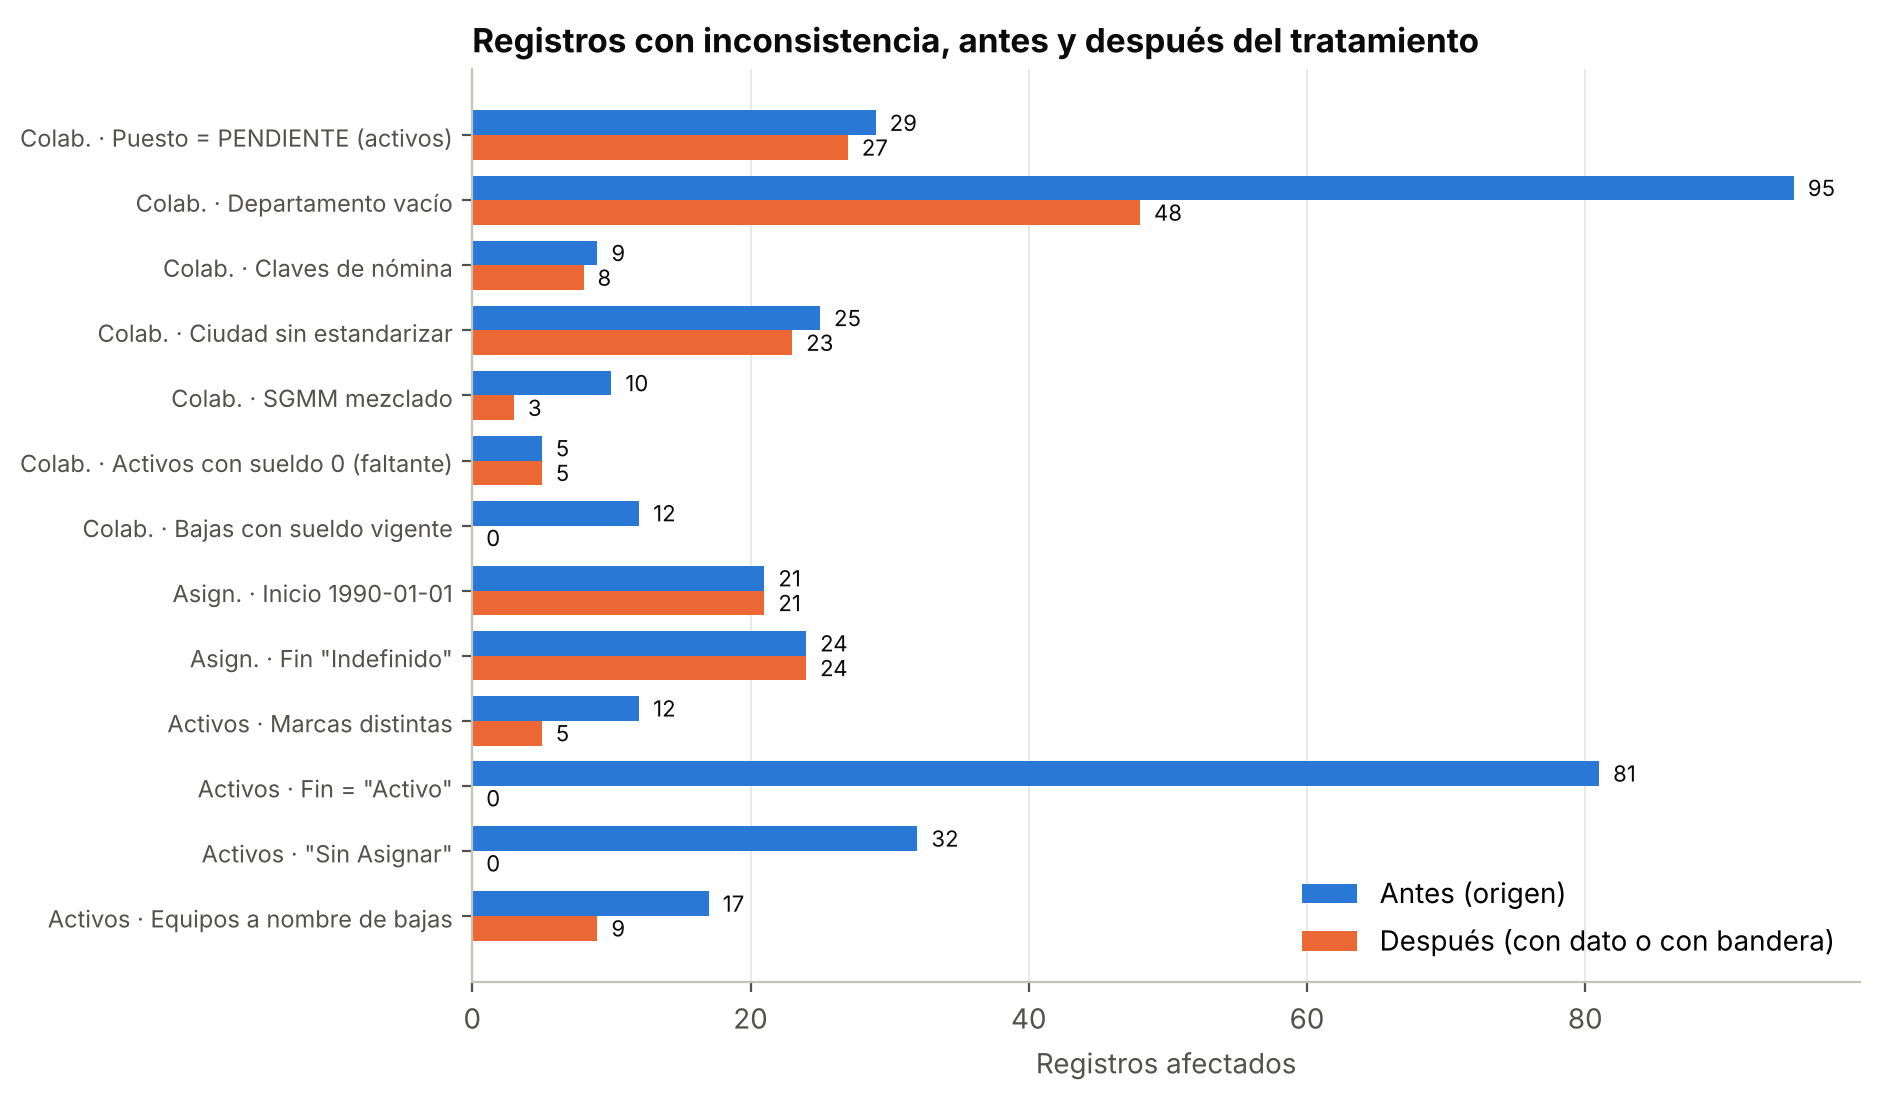

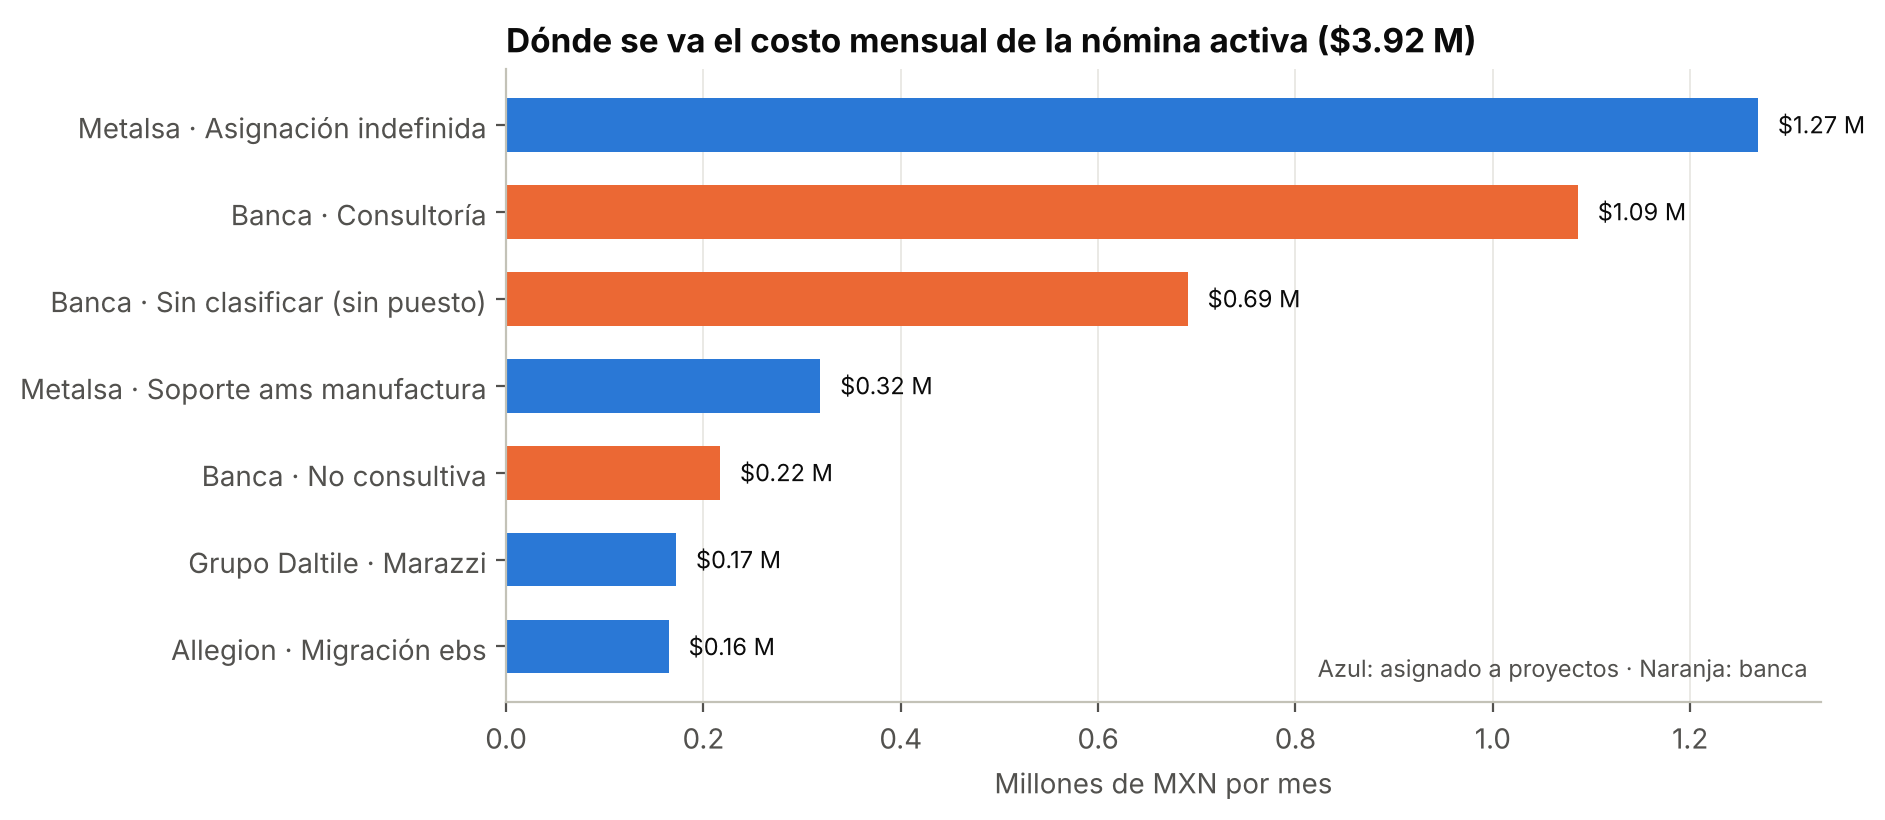

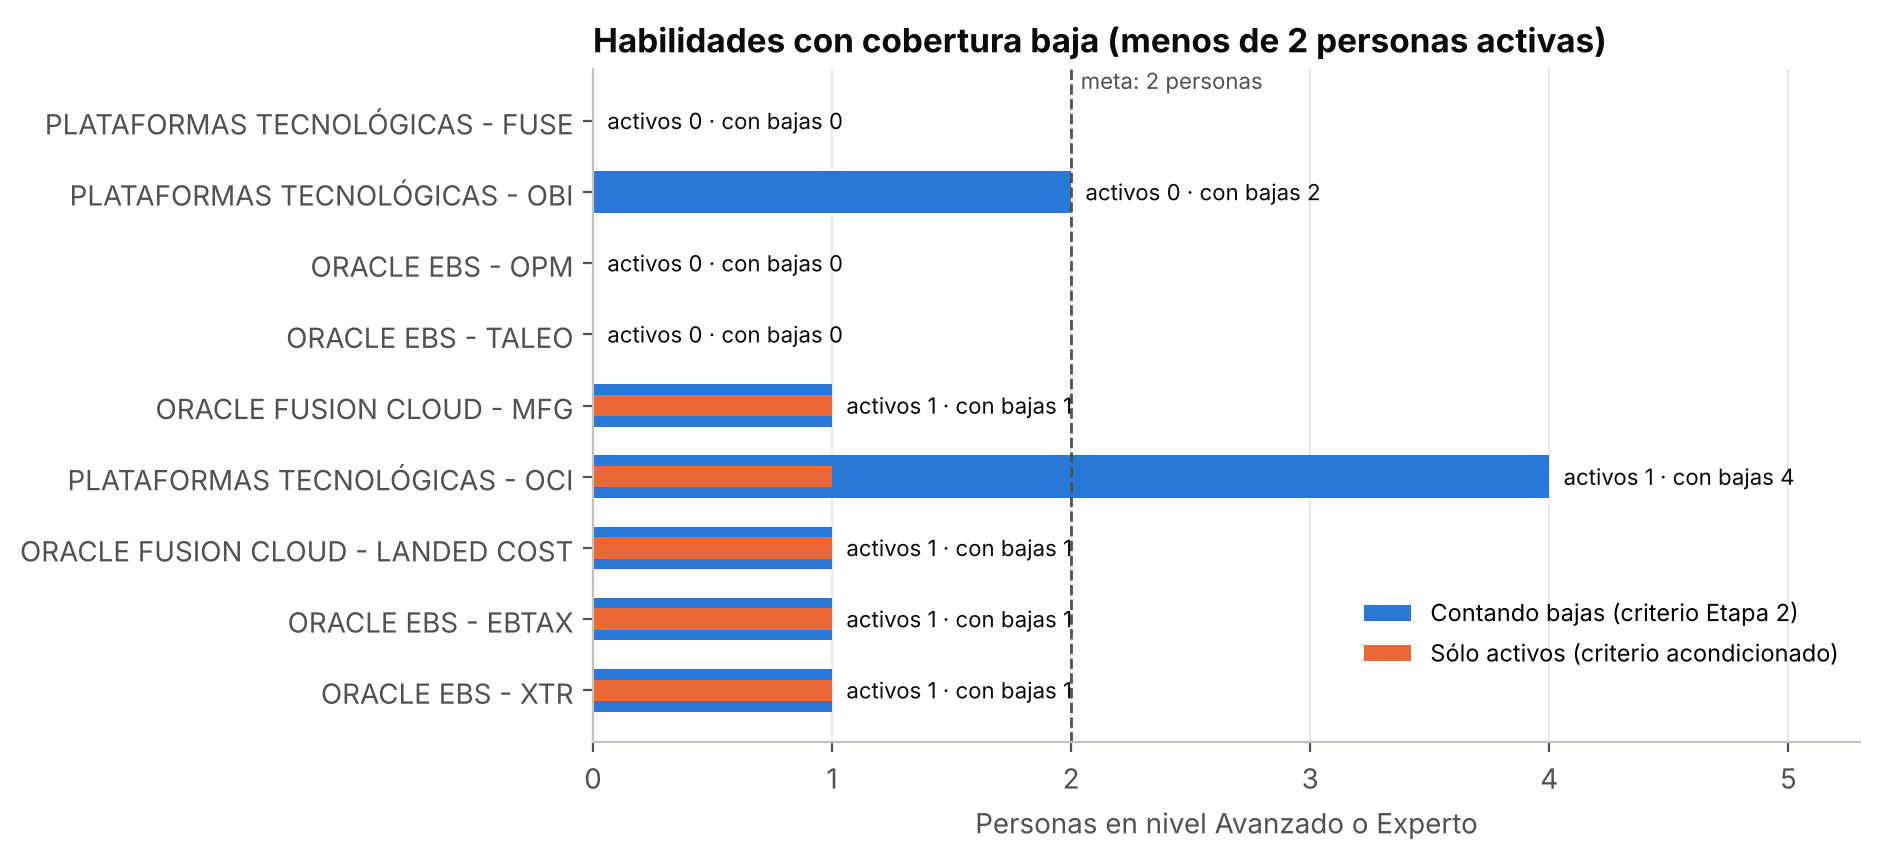

In [16]:
AZUL, NARANJA, TINTA, GRIS = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': GRIS,
                     'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.titlecolor': TINTA, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
IMG = os.path.join(OUT_DIR, 'img'); os.makedirs(IMG, exist_ok=True)

# Fig 1: antes vs después de los problemas con dato faltante / marcador (sólo correcciones con conteo comparable)
CLAVES_F1 = [('Colaboradores', 'Puesto', 'Puesto = PENDIENTE en activos'), ('Colaboradores', 'Departamento', 'Departamento vacío'), ('Colaboradores', 'Tipo Nómina', 'Claves solapadas de la familia SMR'),
             ('Colaboradores', 'Ciudad', 'Ciudad sin estandarizar (MTY/Monterrey, Jalisco/Guadalajara, país, texto libre)'), ('Colaboradores', 'SGMM', 'Valores mezclados (PLAN SEGURO/PLAN SEGUROS, SI/NO, PENDIENTE...)'),
             ('Colaboradores', 'Sueldo Total Integrado', 'Activos con sueldo = 0'), ('Colaboradores', 'Sueldo Total Integrado', 'Bajas que conservan sueldo > 0'),
             ('Asignaciones', 'Fecha Inicio', 'Fecha de relleno 1990-01-01'), ('Asignaciones', 'Fecha Fin', 'Texto "Indefinido" en un campo de fecha'),
             ('Activos', 'Marca', 'Misma marca escrita de varias formas'), ('Activos', 'Fecha Fin', 'Texto "Activo" en un campo de fecha'),
             ('Activos', 'Colaborador Asignado', 'Responsable ligado por nombre y marcador "Sin Asignar"'), ('Activos', 'situacion_equipo', 'Equipos a nombre de bajas sin distinguir si ya se devolvieron')]
f1 = pd.concat([fix[(fix.tabla == t_) & (fix.campo == c_) & (fix.problema == p_)] for t_, c_, p_ in CLAVES_F1]).copy()
ETQ = ['Colab. · Puesto = PENDIENTE (activos)', 'Colab. · Departamento vacío', 'Colab. · Claves de nómina', 'Colab. · Ciudad sin estandarizar', 'Colab. · SGMM mezclado',
       'Colab. · Activos con sueldo 0 (faltante)', 'Colab. · Bajas con sueldo vigente', 'Asign. · Inicio 1990-01-01', 'Asign. · Fin "Indefinido"', 'Activos · Marcas distintas',
       'Activos · Fin = "Activo"', 'Activos · "Sin Asignar"', 'Activos · Equipos a nombre de bajas']
f1['etq'] = ETQ
f1 = f1.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.6))
y = np.arange(len(f1)); h = 0.38
ax.barh(y + h / 2, f1.afectados_antes, h, color=AZUL, label='Antes (origen)')
ax.barh(y - h / 2, f1.pendientes_despues, h, color=NARANJA, label='Después (con dato o con bandera)')
for yi, (a_, d_) in enumerate(zip(f1.afectados_antes, f1.pendientes_despues)):
    ax.text(a_ + 1, yi + h / 2, str(a_), va='center', fontsize=8, color=TINTA); ax.text(d_ + 1, yi - h / 2, str(d_), va='center', fontsize=8, color=TINTA)
ax.set_yticks(y); ax.set_yticklabels(f1.etq, fontsize=8.5); ax.set_xlabel('Registros afectados'); ax.set_title('Registros con inconsistencia, antes y después del tratamiento')
ax.legend(frameon=False, loc='lower right'); ax.grid(axis='x', color='#e6e5e0', lw=.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(os.path.join(IMG, 'fig1_antes_despues.png'), dpi=170); plt.show()

# Fig 2: costo mensual de la nómina activa: proyectos vs banca
partes = res_costo_proyecto.assign(etq=lambda d: d.cliente.str.title() + ' · ' + d.proyecto.str.capitalize()).set_index('etq').costo_mensual.to_dict()
tbb = act_[act_.en_banca].groupby('tipo_banca').costo_mensual_banca.sum()
data = {**{k: v for k, v in partes.items()}, **{'Banca · ' + k.replace('BANCA ', '').capitalize(): v for k, v in tbb.items()}}
ser = pd.Series(data).sort_values()
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols_ = [NARANJA if k.startswith('Banca') else AZUL for k in ser.index]
ax.barh(ser.index, ser.values / 1e6, color=cols_, height=.62)
for i_, v_ in enumerate(ser.values): ax.text(v_ / 1e6 + .02, i_, f'${v_ / 1e6:,.2f} M', va='center', fontsize=8.5, color=TINTA)
ax.set_xlabel('Millones de MXN por mes'); ax.set_title('Dónde se va el costo mensual de la nómina activa ($3.92 M)')
ax.grid(axis='x', color='#e6e5e0', lw=.6); ax.set_axisbelow(True)
ax.text(.99, .04, 'Azul: asignado a proyectos · Naranja: banca', transform=ax.transAxes, ha='right', fontsize=8.5, color=GRIS)
plt.tight_layout(); plt.savefig(os.path.join(IMG, 'fig2_costo_proyectos_banca.png'), dpi=170); plt.show()

# Fig 3: cobertura de habilidades con menos de 2 activos en nivel Avanzado/Experto
cb3 = cov_final[cov_final.cobertura_baja & ~cov_final.sin_evaluaciones].sort_values('n_nivel3plus_activos', ascending=False)
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.barh(cb3.habilidad, cb3.n_nivel3plus_incl_bajas, color=AZUL, height=.6, label='Contando bajas (criterio Etapa 2)')
ax.barh(cb3.habilidad, cb3.n_nivel3plus_activos, color=NARANJA, height=.3, label='Sólo activos (criterio acondicionado)')
ax.axvline(2, color=GRIS, lw=1, ls='--'); ax.text(2.04, len(cb3) - .55, 'meta: 2 personas', fontsize=8, color=GRIS)
for i_, (a_, b_) in enumerate(zip(cb3.n_nivel3plus_activos, cb3.n_nivel3plus_incl_bajas)):
    ax.text(max(a_, b_) + .06, i_, f'activos {a_} · con bajas {b_}', va='center', fontsize=8, color=TINTA)
ax.set_xlim(0, 5.3)
ax.set_xlabel('Personas en nivel Avanzado o Experto'); ax.set_title('Habilidades con cobertura baja (menos de 2 personas activas)')
ax.legend(frameon=False, loc='lower right', fontsize=8.5, bbox_to_anchor=(1, .08)); ax.grid(axis='x', color='#e6e5e0', lw=.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig(os.path.join(IMG, 'fig3_cobertura_habilidades.png'), dpi=170); plt.show()

## 14. Exportación de resultados (CSV y Excel)

In [17]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
for t, df in TABLAS.items():
    df.to_csv(os.path.join(OUT_DIR, f'{t}.csv'), index=False, encoding='utf-8-sig')
fix.to_csv(os.path.join(OUT_DIR, 'bitacora_correcciones.csv'), index=False, encoding='utf-8-sig')
val.to_csv(os.path.join(OUT_DIR, 'validaciones.csv'), index=False, encoding='utf-8-sig')
metadata.to_csv(os.path.join(OUT_DIR, 'metadata_tablas.csv'), index=False, encoding='utf-8-sig')
metricas.to_csv(os.path.join(OUT_DIR, 'metricas_preguntas.csv'), index=False, encoding='utf-8-sig')

LEEME = pd.DataFrame({'contenido': [
 'OT Consulting · Datos acondicionados (Etapa 3) · fecha de corte 17-nov-2026',
 'Hojas con prefijo "t_" = tablas acondicionadas; "meta_" = metadata; "bitacora_" y "validaciones" = evidencia; "res_" = resultados por pregunta.',
 'Reglas de negocio R01-R12 y métodos M01-M11: ver el documento de Etapa 3 y el cuaderno OTC_Etapa3_Acondicionamiento.ipynb.',
 'Los datos personales enmascarados y sin uso analítico se excluyeron (R12).']})
hojas = [('LEEME', LEEME), ('meta_tablas', resumen_tablas), ('meta_columnas', metadata), ('bitacora_correcciones', fix), ('validaciones', val), ('res_metricas', metricas),
         ('t_colaboradores', col_final), ('t_asignaciones', asig_final), ('t_proyectos', proy_final), ('t_activos', act_final), ('t_habilidades_largo', hab_ln),
         ('t_habilidades_cobertura', cov_final), ('t_roles', roles_out), ('t_departamentos', dep_out), ('res_costo_proyecto', res_costo_proyecto), ('res_costo_cliente', res_costo_cliente),
         ('res_costo_hora_esquema', res_esquema), ('res_bajas_mes', bm), ('res_bajas_puesto', res_bajas_puesto), ('res_equipos', res_equipos)]
xlsx = os.path.join(OUT_DIR, 'OTC_datos_acondicionados.xlsx')
with pd.ExcelWriter(xlsx, engine='openpyxl', datetime_format='YYYY-MM-DD') as w:
    for nombre, df in hojas:
        df.to_excel(w, sheet_name=nombre[:31], index=False)
        ws = w.sheets[nombre[:31]]
        for j, col in enumerate(df.columns, start=1):
            cel = ws.cell(row=1, column=j); cel.font = Font(bold=True, color='FFFFFF'); cel.fill = PatternFill('solid', fgColor='1F3A5F'); cel.alignment = Alignment(wrap_text=True, vertical='center')
            largo_ = max([len(str(col))] + [len(str(x)) for x in df[col].head(60).tolist()])
            ws.column_dimensions[get_column_letter(j)].width = min(max(10, largo_ + 2), 55)
        ws.freeze_panes = 'A2'
        ws.auto_filter.ref = ws.dimensions
print('Archivos generados en', OUT_DIR); print(sorted(os.listdir(OUT_DIR)))

Archivos generados en /home/claude/work/data/salida
['OTC_datos_acondicionados.xlsx', 'activos_acondicionada.csv', 'asignaciones_acondicionada.csv', 'bitacora_correcciones.csv', 'colaboradores_acondicionada.csv', 'departamentos.csv', 'habilidades_cobertura.csv', 'habilidades_colaborador.csv', 'img', 'metadata_tablas.csv', 'metricas_preguntas.csv', 'proyectos_acondicionada.csv', 'roles.csv', 'validaciones.csv']
